In [1]:
# ==============================================================================
# STAGE 0: STRICTLY READ-ONLY AUDIT OF cws_project (ZERO FILE MODIFICATIONS)
# ==============================================================================
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Locate cws_project dynamically (works from root, Code/, or anywhere on Desktop)
cwd = Path.cwd().resolve()
if cwd.name == "cws_project":
    PROJECT_ROOT = cwd
elif cwd.parent.name == "cws_project":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path.home() / "Desktop" / "cws_project"

print("=" * 80)
print(f"STAGE 0 READ-ONLY AUDIT | PROJECT ROOT: {PROJECT_ROOT}")
print(f"Directory exists: {PROJECT_ROOT.exists()}")
print("=" * 80)

# 2. Check Python Environment & Key Packages
print("\n[1] PYTHON & PACKAGE ENVIRONMENT AUDIT")
print(f"Python version: {sys.version.split()[0]} | Executable: {sys.executable}")

packages = [
    ("numpy", "numpy"),
    ("scipy", "scipy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("scikit-learn", "sklearn"),
    ("xgboost", "xgboost"),
    ("torch", "torch"),
    ("scikit-optimize", "skopt"),
    ("optuna", "optuna"),
    ("astra-toolbox", "astra"),
    ("gVXR", "gvxr"),
]

for label, mod_name in packages:
    try:
        mod = __import__(mod_name)
        ver = getattr(mod, "__version__", "installed (no __version__)")
        print(f"  [OK] {label:<18}: {ver}")
    except ImportError:
        print(f"  [--] {label:<18}: NOT INSTALLED")

# Check ASTRA GPU / CUDA & 2D vs 3D FDK support specifically
try:
    import astra
    has_cuda = astra.use_cuda()
    print(f"  -> ASTRA CUDA available : {has_cuda}")
except Exception as e:
    print(f"  -> ASTRA check error    : {e}")

# 3. Complete Read-Only Directory & File Inventory
print("\n" + "=" * 80)
print("[2] COMPLETE DIRECTORY & FILE INVENTORY")
print("=" * 80)
if PROJECT_ROOT.exists():
    all_paths = sorted(PROJECT_ROOT.rglob("*"))
    dirs = [p for p in all_paths if p.is_dir() and ".ipynb_checkpoints" not in str(p)]
    files = [p for p in all_paths if p.is_file() and ".ipynb_checkpoints" not in str(p)]
    
    print(f"Folders ({len(dirs)}):")
    for d in dirs:
        print(f"  [DIR]  {d.relative_to(PROJECT_ROOT)}/")
        
    print(f"\nFiles ({len(files)}):")
    npy_files = []
    csv_files = []
    code_files = []
    for f in files:
        rel = f.relative_to(PROJECT_ROOT)
        size_kb = f.stat().st_size / 1024.0
        if f.suffix.lower() == ".npy":
            npy_files.append(f)
        elif f.suffix.lower() == ".csv":
            csv_files.append(f)
        elif f.suffix.lower() in [".py", ".ipynb"]:
            code_files.append(f)
        # Print all non-.npy files directly; summarize .npy if there are many
        if f.suffix.lower() != ".npy" or len(files) <= 40:
            print(f"  [FILE] {str(rel):<52} | {size_kb:>9.1f} KB")
    if len(npy_files) > 0:
        print(f"\n  Total .npy files found: {len(npy_files)}")
        # Inspect up to 3 sample .npy files for shape and dtype
        for nf in npy_files[:3]:
            try:
                arr = np.load(nf, allow_pickle=False)
                print(f"    Sample .npy: {nf.relative_to(PROJECT_ROOT)} -> shape={arr.shape}, dtype={arr.dtype}, min={np.nanmin(arr):.4g}, max={np.nanmax(arr):.4g}")
            except Exception as e:
                print(f"    Sample .npy: {nf.relative_to(PROJECT_ROOT)} -> load error: {e}")

# 4. Deep Physical & Statistical Audit of Existing CSV Datasets
print("\n" + "=" * 80)
print(f"[3] AUDIT OF EXISTING CSV FILES ({len(csv_files)} found)")
print("=" * 80)

for cf in csv_files:
    rel_cf = cf.relative_to(PROJECT_ROOT)
    print(f"\n--- CSV FILE: {rel_cf} ---")
    try:
        df = pd.read_csv(cf)
        print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
        print(f"Columns: {list(df.columns)}")
        
        # Check NaNs and Infs
        nan_counts = df.isna().sum()
        nan_cols = nan_counts[nan_counts > 0].to_dict()
        num_df = df.select_dtypes(include=[np.number])
        inf_counts = np.isinf(num_df).sum()
        inf_cols = inf_counts[inf_counts > 0].to_dict()
        print(f"NaN columns: {nan_cols if nan_cols else 'None'}")
        print(f"Inf columns: {inf_cols if inf_cols else 'None'}")
        
        # Check categorical / string / low-cardinality columns (material, geometry, flags)
        for col in df.columns:
            if df[col].dtype == "object" or df[col].nunique(dropna=False) <= 10:
                vc = df[col].value_counts(dropna=False).to_dict()
                print(f"  Value counts [{col}]: {vc}")
                
        # Numerical summary (min, 5%, 50%, 95%, max)
        if not num_df.empty:
            stats = num_df.describe(percentiles=[0.05, 0.5, 0.95]).T[["count", "mean", "std", "min", "5%", "50%", "95%", "max"]]
            print("\nNumerical Summary:")
            print(stats.to_string(float_format=lambda x: f"{x:.4g}"))
            
        # Physical sanity checks on SNR / CNR / photon counts if present
        for metric_key in ["snr", "cnr", "scan_time", "photon", "trans", "starv"]:
            matching_cols = [c for c in num_df.columns if metric_key in c.lower()]
            for mc in matching_cols:
                n_neg = int((num_df[mc] < 0).sum())
                n_zero = int((num_df[mc] == 0).sum())
                print(f"  Sanity check [{mc}]: <0 count = {n_neg}, ==0 count = {n_zero}, min = {num_df[mc].min():.4g}, max = {num_df[mc].max():.4g}")
    except Exception as e:
        print(f"  Error reading {rel_cf}: {e}")

# 5. Read-Only Summary of Existing Code / Notebooks
print("\n" + "=" * 80)
print(f"[4] AUDIT OF EXISTING CODE & NOTEBOOKS ({len(code_files)} found)")
print("=" * 80)

for cf in code_files:
    rel_cf = cf.relative_to(PROJECT_ROOT)
    print(f"\n--- CODE FILE: {rel_cf} ---")
    try:
        if cf.suffix.lower() == ".py":
            text = cf.read_text(encoding="utf-8", errors="replace")
            lines = text.splitlines()
            print(f"Total lines: {len(lines)}")
            for i, line in enumerate(lines, 1):
                s = line.strip()
                if s.startswith(("def ", "class ", "import ", "from ")) or "astra" in s.lower() or "poisson" in s.lower() or "fdk" in s.lower() or "fbp" in s.lower():
                    print(f"  L{i:03d}: {line[:100]}")
        elif cf.suffix.lower() == ".ipynb":
            nb = json.loads(cf.read_text(encoding="utf-8", errors="replace"))
            cells = nb.get("cells", [])
            code_cells = [c for c in cells if c.get("cell_type") == "code"]
            md_cells = [c for c in cells if c.get("cell_type") == "markdown"]
            print(f"Notebook cells: {len(cells)} total ({len(code_cells)} code, {len(md_cells)} markdown)")
            for idx, c in enumerate(cells):
                src = "".join(c.get("source", []))
                first_lines = [ln.strip() for ln in src.splitlines() if ln.strip()][:3]
                preview = " | ".join(first_lines)[:110]
                print(f"  Cell {idx:02d} [{c.get('cell_type', '')[:4]}]: {preview}")
    except Exception as e:
        print(f"  Error inspecting {rel_cf}: {e}")

print("\n" + "=" * 80)
print("STAGE 0 READ-ONLY AUDIT COMPLETE.")
print("=" * 80)

STAGE 0 READ-ONLY AUDIT | PROJECT ROOT: C:\Users\Bhargav Lakhineni\Desktop\cws_project
Directory exists: True

[1] PYTHON & PACKAGE ENVIRONMENT AUDIT
Python version: 3.10.21 | Executable: C:\Anaconda3\envs\ct-project\python.exe
  [OK] numpy             : 2.2.5
  [OK] scipy             : 1.15.3
  [OK] pandas            : 2.3.3
  [OK] matplotlib        : 3.10.9
  [OK] scikit-learn      : 1.7.2
  [OK] xgboost           : 3.2.0
  [--] torch             : NOT INSTALLED
  [--] scikit-optimize   : NOT INSTALLED


C:\Anaconda3\envs\ct-project\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  [OK] optuna            : 5.0.0
  [OK] astra-toolbox     : 2.5.0
  [--] gVXR              : NOT INSTALLED
  -> ASTRA CUDA available : True

[2] COMPLETE DIRECTORY & FILE INVENTORY
Folders (17):
  [DIR]  Code/
  [DIR]  Code\.virtual_documents/
  [DIR]  Code\__pycache__/
  [DIR]  Code\anaconda_projects/
  [DIR]  Code\anaconda_projects\db/
  [DIR]  Data/
  [DIR]  Data\Extrapolation/
  [DIR]  Data\Pilot/
  [DIR]  Data\Raw_Sweep/
  [DIR]  Data\Reference/
  [DIR]  Data\Slices/
  [DIR]  Data\Testing/
  [DIR]  Data\Training/
  [DIR]  Data\Validation/
  [DIR]  Docs/
  [DIR]  Figures/
  [DIR]  Models/

Files (87):
  [FILE] Code\.virtual_documents\Untitled.ipynb               |      31.8 KB
  [FILE] Code\__pycache__\ct_simulator.cpython-310.pyc        |      11.1 KB
  [FILE] Code\anaconda_projects\db\project_filebrowser.db     |      32.0 KB
  [FILE] Code\ct_simulator.py                                 |      17.0 KB
  [FILE] Code\Demo_Worked_Recommendation.ipynb                |       2.5 KB
  

In [2]:
# ==============================================================================
# STAGE 0B: READ-ONLY LOCATOR FOR CONDA ENVS & PREVIOUS CT DATASET/CODE
# ==============================================================================
import os
import subprocess
from pathlib import Path
import pandas as pd

HOME = Path.home()
print("=" * 80)
print(f"STAGE 0B LOCATOR | USER HOME: {HOME}")
print("=" * 80)

# 1. Discover all Conda Environments and inspect packages inside each
print("\n[1] SEARCHING FOR CONDA ENVIRONMENTS (ASTRA / gVXR / XGBOOST)")
conda_env_dirs = [
    Path("C:/Anaconda3/envs"),
    HOME / ".conda" / "envs",
    HOME / "anaconda3" / "envs",
    HOME / "miniconda3" / "envs",
    Path("C:/Miniconda3/envs"),
]

env_txt = HOME / ".conda" / "environments.txt"
discovered_envs = [Path("C:/Anaconda3")]
if env_txt.exists():
    for line in env_txt.read_text(encoding="utf-8", errors="ignore").splitlines():
        p = Path(line.strip())
        if p.exists() and p not in discovered_envs:
            discovered_envs.append(p)

for d in conda_env_dirs:
    if d.exists():
        for sub in d.iterdir():
            if sub.is_dir() and sub not in discovered_envs:
                discovered_envs.append(sub)

for env_path in discovered_envs:
    py_exe = env_path / "python.exe"
    if py_exe.exists():
        cmd = [
            str(py_exe), "-c",
            "import sys; pkgs=[]; "
            "[pkgs.append(m) for m in ['astra','gvxr','xgboost','torch','skopt','optuna','skimage'] "
            "if __import__('importlib.util').util.find_spec(m) is not None]; "
            "print(f'Py {sys.version.split()[0]} | Found: {pkgs}')"
        ]
        try:
            out = subprocess.check_output(cmd, stderr=subprocess.STDOUT, text=True, timeout=10).strip()
            print(f"  [ENV] {str(env_path):<42} -> {out}")
        except Exception as e:
            print(f"  [ENV] {str(env_path):<42} -> check error: {e}")

# 2. Search Desktop, Documents, Downloads, OneDrive for previous CT CSVs or Code
print("\n" + "=" * 80)
print("[2] SEARCHING FOR PREVIOUS CT PROJECT FILES (.csv, .py, .ipynb)")
print("=" * 80)

search_roots = [
    HOME / "Desktop",
    HOME / "Documents",
    HOME / "Downloads",
    HOME / "OneDrive",
]

keywords = ["ct", "snr", "cnr", "surrogate", "astra", "extrap", "sweep", "phantom", "project", "kV", "mas", "beer", "fdk"]
found_csvs = []
found_code = []

skip_dirs = {"AppData", ".conda", ".ipython", ".matplotlib", ".cache", "node_modules", ".git", "anaconda3", "Anaconda3", "Lib", "site-packages"}

for root in search_roots:
    if not root.exists():
        continue
    for dirpath, dirnames, filenames in os.walk(root):
        # Prune deep/system directories for fast execution
        dirnames[:] = [d for d in dirnames if d not in skip_dirs and not d.startswith(".")]
        rel_depth = len(Path(dirpath).relative_to(root).parts)
        if rel_depth > 4:
            dirnames[:] = []
            continue
        for fn in filenames:
            fpath = Path(dirpath) / fn
            ext = fpath.suffix.lower()
            name_low = str(fpath).lower()
            if ext == ".csv":
                if any(k in name_low for k in keywords) or fpath.stat().st_size > 20_000:
                    found_csvs.append(fpath)
            elif ext in [".py", ".ipynb"] and "cws_project" not in name_low:
                if any(k in name_low for k in keywords):
                    found_code.append(fpath)

print(f"Candidate CSV files found ({len(found_csvs)}):")
for cf in found_csvs[:25]:
    try:
        df_head = pd.read_csv(cf, nrows=5)
        cols = list(df_head.columns)
        # Count total lines quickly
        with open(cf, "rb") as f:
            n_rows = sum(1 for _ in f) - 1
        print(f"  [CSV] {str(cf)} | ~{n_rows} rows | cols={cols[:8]}")
    except Exception:
        print(f"  [CSV] {str(cf)} | ({cf.stat().st_size/1024:.1f} KB)")

print(f"\nCandidate Code/Notebook files found ({len(found_code)}):")
for kf in found_code[:25]:
    print(f"  [CODE] {str(kf)} | ({kf.stat().st_size/1024:.1f} KB)")

print("\n" + "=" * 80)
print("STAGE 0B LOCATOR COMPLETE.")
print("=" * 80)

STAGE 0B LOCATOR | USER HOME: C:\Users\Bhargav Lakhineni

[1] SEARCHING FOR CONDA ENVIRONMENTS (ASTRA / gVXR / XGBOOST)
  [ENV] C:\Anaconda3                               -> Py 3.14.6 | Found: ['skimage']
  [ENV] C:\Anaconda3\envs\ct-project               -> Py 3.10.21 | Found: ['astra', 'xgboost', 'optuna']

[2] SEARCHING FOR PREVIOUS CT PROJECT FILES (.csv, .py, .ipynb)
Candidate CSV files found (17):
  [CSV] C:\Users\Bhargav Lakhineni\Desktop\cws_project\Data\Extrapolation\extrapolation_test_data.csv | ~397 rows | cols=['config_id', 'material', 'material_code', 'geometry_type', 'geometry_code', 'sample_size_mm', 'density_scale', 'bulk_density_g_cm3']
  [CSV] C:\Users\Bhargav Lakhineni\Desktop\cws_project\Data\Pilot\pilot_30_summary.csv | ~30 rows | cols=['config_id', 'material', 'material_code', 'geometry_type', 'geometry_code', 'sample_size_mm', 'density_scale', 'bulk_density_g_cm3']
  [CSV] C:\Users\Bhargav Lakhineni\Desktop\cws_project\Data\Raw_Sweep\checkpoint_all_simulations.cs

In [3]:
# ==============================================================================
# PATCH & RUN: UPDATE ct_simulator.py WITH 'time' IMPORT & EXECUTE PILOT
# ==============================================================================
import sys
import time 
from pathlib import Path
import numpy as np
import pandas as pd
import importlib
import astra

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name != "cws_project":
    PROJECT_ROOT = Path.home() / "Desktop" / "cws_project"

# Update ct_simulator.py code with 'import time' included at the top
sim_code = '''# ==============================================================================
# MODULE: ct_simulator.py
# Functional Polychromatic Beer-Lambert + Poisson CT Simulator with ASTRA
# ==============================================================================
import time
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.ndimage import distance_transform_edt
import astra

MATERIAL_PROPS = {
    "Polymer_PMMA": {"code": 0, "rho_0": 1.18, "z_eff": 6.5,  "inc_mat": "Aluminium", "inc_rho": 2.70},
    "Aluminium":    {"code": 1, "rho_0": 2.70, "z_eff": 13.0, "inc_mat": "Polymer_PMMA", "inc_rho": 1.18},
    "Steel":        {"code": 2, "rho_0": 7.87, "z_eff": 26.0, "inc_mat": "Aluminium", "inc_rho": 2.70},
}

GEOMETRY_CODES = {"cylinder": 0, "ellipse": 1, "block": 2}

def load_nist_table(project_root):
    csv_path = Path(project_root) / "Data" / "Reference" / "nist_xcom_attenuation.csv"
    return pd.read_csv(csv_path)

def get_energy_grid(e_min=12.0, e_max=220.0, step_kev=2.0):
    return np.arange(e_min, e_max + 0.1, step_kev, dtype=np.float64)

def evaluate_mu_rho(energies_kev, material_name, nist_df):
    col = f"mu_rho_{material_name}_cm2_g"
    return np.exp(np.interp(np.log(energies_kev), np.log(nist_df["energy_keV"].values), np.log(nist_df[col].values)))

def generate_polychromatic_spectrum(
    energies_kev, kv, mas_per_proj, filter_cu_mm, nist_df,
    intrinsic_al_mm=1.5, flux_constant=260.0
):
    de = float(energies_kev[1] - energies_kev[0]) if len(energies_kev) > 1 else 1.0
    brem = np.maximum(kv - energies_kev, 0.0) / energies_kev
    
    char = np.zeros_like(energies_kev)
    if kv > 69.5:
        char_scale = 0.08 * ((kv - 69.5) ** 1.63)
        for e_line, rel_w in [(58.0, 0.25), (59.3, 0.50), (67.2, 0.15)]:
            char += char_scale * rel_w * np.exp(-0.5 * ((energies_kev - e_line) / (0.8 * de)) ** 2)
            
    raw_spec = (brem + char) * (energies_kev <= kv)
    
    mu_al = evaluate_mu_rho(energies_kev, "Aluminium", nist_df) * 2.70
    mu_cu = evaluate_mu_rho(energies_kev, "Copper", nist_df) * 8.96
    
    trans_filter = np.exp(-mu_al * (intrinsic_al_mm * 0.1) - mu_cu * (filter_cu_mm * 0.1))
    n0_e = flux_constant * mas_per_proj * raw_spec * trans_filter * de
    return np.maximum(n0_e, 0.0)

def create_parametrised_phantom(
    n_grid=128, fov_mm=32.0, material="Aluminium", geometry_type="cylinder",
    sample_size_mm=14.0, density_scale=1.0
):
    pixel_size_mm = fov_mm / float(n_grid)
    pixel_size_cm = pixel_size_mm * 0.1
    coords = (np.arange(n_grid) - (n_grid - 1) / 2.0) * pixel_size_mm
    X, Y = np.meshgrid(coords, coords)
    
    radius_mm = 0.5 * sample_size_mm
    if geometry_type == "cylinder":
        outer_mask = (X**2 + Y**2) <= (radius_mm**2)
    elif geometry_type == "ellipse":
        a_mm = radius_mm * 1.15
        b_mm = radius_mm * 0.85
        outer_mask = ((X / a_mm)**2 + (Y / b_mm)**2) <= 1.0
    elif geometry_type == "block":
        half_w = radius_mm * 0.90
        half_h = radius_mm * 0.85
        outer_mask = (np.abs(X) <= half_w) & (np.abs(Y) <= half_h)
    else:
        raise ValueError(f"Unknown geometry_type: {geometry_type}")
        
    r_inc_mm = max(0.24 * radius_mm, 1.60)
    x_offset_mm = 0.42 * radius_mm
    
    inc_mask = ((X - x_offset_mm)**2 + Y**2) <= (r_inc_mm**2)
    inc_mask = inc_mask & outer_mask
    
    air_void_mask = ((X + x_offset_mm)**2 + (Y - 0.15 * radius_mm)**2) <= ((0.75 * r_inc_mm)**2)
    air_void_mask = air_void_mask & outer_mask & (~inc_mask)
    
    matrix_mask = outer_mask & (~inc_mask) & (~air_void_mask)
    
    dist_inc = distance_transform_edt(inc_mask)
    roi_inc = dist_inc >= 1.5
    if np.sum(roi_inc) < 12:
        roi_inc = inc_mask.copy()
        
    dist_mat = distance_transform_edt(matrix_mask)
    roi_bg = (dist_mat >= 2.0) & (np.abs(Y) >= 0.22 * radius_mm) & (np.abs(X) <= 0.45 * radius_mm)
    if np.sum(roi_bg) < 25:
        roi_bg = dist_mat >= 1.5
    if np.sum(roi_bg) < 15:
        roi_bg = matrix_mask.copy()
        
    R_radial = np.sqrt(X**2 + Y**2)
    roi_center = matrix_mask & (R_radial <= 0.35 * radius_mm)
    roi_perim = matrix_mask & (R_radial >= 0.65 * radius_mm) & (R_radial <= 0.88 * radius_mm)
    
    return {
        "n_grid": n_grid,
        "fov_mm": fov_mm,
        "pixel_size_mm": pixel_size_mm,
        "pixel_size_cm": pixel_size_cm,
        "material": material,
        "geometry_type": geometry_type,
        "sample_size_mm": sample_size_mm,
        "density_scale": density_scale,
        "outer_mask": outer_mask,
        "matrix_mask": matrix_mask,
        "inc_mask": inc_mask,
        "air_void_mask": air_void_mask,
        "roi_inc": roi_inc,
        "roi_bg": roi_bg,
        "roi_center": roi_center,
        "roi_perim": roi_perim,
        "inc_center_xy_mm": (x_offset_mm, 0.0),
        "inc_radius_mm": r_inc_mm,
    }

def detect_astra_engine():
    if astra.use_cuda():
        try:
            vg = astra.create_vol_geom(32, 32, 1)
            angles = np.linspace(0, 2 * np.pi, 16, endpoint=False)
            pg = astra.create_proj_geom("cone", 1.0, 1.0, 1, 48, angles, 300.0, 100.0)
            vol_id = astra.data3d.create("-vol", vg, np.ones((1, 32, 32), dtype=np.float32))
            sino_id = astra.data3d.create("-sino", pg, np.zeros((1, 16, 48), dtype=np.float32))
            cfg_fp = astra.astra_dict("FP3D_CUDA")
            cfg_fp["VolumeDataId"] = vol_id
            cfg_fp["ProjectionDataId"] = sino_id
            alg_fp = astra.algorithm.create(cfg_fp)
            astra.algorithm.run(alg_fp)
            astra.algorithm.delete(alg_fp)
            
            cfg_fdk = astra.astra_dict("FDK_CUDA")
            cfg_fdk["ProjectionDataId"] = sino_id
            cfg_fdk["ReconstructionDataId"] = vol_id
            alg_fdk = astra.algorithm.create(cfg_fdk)
            astra.algorithm.run(alg_fdk)
            astra.algorithm.delete(alg_fdk)
            astra.data3d.delete([vol_id, sino_id])
            return "3D_FDK_CUDA"
        except Exception:
            pass
    return "2D_FBP_CPU"

ASTRA_ENGINE = detect_astra_engine()

def astra_forward_project_mask(mask_2d, n_projections, pixel_size_cm, engine=ASTRA_ENGINE):
    n_grid = mask_2d.shape[0]
    n_det = int(np.ceil(n_grid * 1.45))
    if n_det % 2 == 1:
        n_det += 1
        
    if engine == "3D_FDK_CUDA":
        angles = np.linspace(0, 2.0 * np.pi, int(n_projections), endpoint=False)
        vg = astra.create_vol_geom(n_grid, n_grid, 1)
        pg = astra.create_proj_geom("cone", 1.3, 1.3, 1, n_det, angles, 400.0, 120.0)
        vol_data = np.expand_dims(mask_2d.astype(np.float32), axis=0)
        vol_id = astra.data3d.create("-vol", vg, vol_data)
        sino_id = astra.data3d.create("-sino", pg, np.zeros((1, len(angles), n_det), dtype=np.float32))
        cfg = astra.astra_dict("FP3D_CUDA")
        cfg["VolumeDataId"] = vol_id
        cfg["ProjectionDataId"] = sino_id
        alg_id = astra.algorithm.create(cfg)
        astra.algorithm.run(alg_id)
        sino = astra.data3d.get(sino_id)[0].copy()
        astra.algorithm.delete(alg_id)
        astra.data3d.delete([vol_id, sino_id])
        return sino * pixel_size_cm
    else:
        angles = np.linspace(0, np.pi, int(n_projections), endpoint=False)
        vg = astra.create_vol_geom(n_grid, n_grid)
        pg = astra.create_proj_geom("parallel", 1.0, n_det, angles)
        proj_id = astra.create_projector("line", pg, vg)
        sino_id, sino = astra.create_sino(mask_2d.astype(np.float32), proj_id)
        astra.data2d.delete(sino_id)
        astra.projector.delete(proj_id)
        return sino.copy() * pixel_size_cm

def astra_reconstruct_slice(sino_log, n_grid, pixel_size_cm, engine=ASTRA_ENGINE):
    n_projections, n_det = sino_log.shape
    if engine == "3D_FDK_CUDA":
        angles = np.linspace(0, 2.0 * np.pi, int(n_projections), endpoint=False)
        vg = astra.create_vol_geom(n_grid, n_grid, 1)
        pg = astra.create_proj_geom("cone", 1.3, 1.3, 1, n_det, angles, 400.0, 120.0)
        sino_3d = np.expand_dims(sino_log.astype(np.float32), axis=0)
        sino_id = astra.data3d.create("-sino", pg, sino_3d)
        rec_id = astra.data3d.create("-vol", vg, np.zeros((1, n_grid, n_grid), dtype=np.float32))
        cfg = astra.astra_dict("FDK_CUDA")
        cfg["ProjectionDataId"] = sino_id
        cfg["ReconstructionDataId"] = rec_id
        alg_id = astra.algorithm.create(cfg)
        astra.algorithm.run(alg_id)
        rec = astra.data3d.get(rec_id)[0].copy()
        astra.algorithm.delete(alg_id)
        astra.data3d.delete([sino_id, rec_id])
        return rec / pixel_size_cm
    else:
        angles = np.linspace(0, np.pi, int(n_projections), endpoint=False)
        vg = astra.create_vol_geom(n_grid, n_grid)
        pg = astra.create_proj_geom("parallel", 1.0, n_det, angles)
        proj_id = astra.create_projector("line", pg, vg)
        sino_id = astra.data2d.create("-sino", pg, sino_log.astype(np.float32))
        rec_id = astra.data2d.create("-vol", vg)
        cfg = astra.astra_dict("FBP")
        cfg["ReconstructionDataId"] = rec_id
        cfg["ProjectionDataId"] = sino_id
        cfg["ProjectorId"] = proj_id
        cfg["option"] = {"FilterType": "ram-lak"}
        alg_id = astra.algorithm.create(cfg)
        astra.algorithm.run(alg_id)
        rec = astra.data2d.get(rec_id).copy()
        astra.algorithm.delete(alg_id)
        astra.data2d.delete([sino_id, rec_id])
        astra.projector.delete(proj_id)
        return rec / pixel_size_cm

def calibrate_reconstruction_scale(engine=ASTRA_ENGINE):
    ph = create_parametrised_phantom(128, 32.0, "Aluminium", "cylinder", 16.0, 1.0)
    mask = ph["outer_mask"].astype(np.float32)
    sino_len = astra_forward_project_mask(mask, 180, ph["pixel_size_cm"], engine=engine)
    true_mu = 1.0
    rec_raw = astra_reconstruct_slice(sino_len * true_mu, 128, ph["pixel_size_cm"], engine=engine)
    measured = float(np.mean(rec_raw[ph["roi_center"]]))
    return 1.0 / measured if measured > 1e-6 else 1.0

RECON_CALIB_FACTOR = calibrate_reconstruction_scale(ASTRA_ENGINE)

def compute_edge_fwhm_mm(recon_img, phantom_dict):
    n_grid = phantom_dict["n_grid"]
    px_mm = phantom_dict["pixel_size_mm"]
    mid_row = n_grid // 2
    profile = recon_img[mid_row, :]
    
    x_coords = (np.arange(n_grid) - (n_grid - 1) / 2.0) * px_mm
    x_edge_expected = phantom_dict["inc_center_xy_mm"][0] - phantom_dict["inc_radius_mm"]
    win_mask = (x_coords >= x_edge_expected - 2.5) & (x_coords <= x_edge_expected + 2.5)
    if np.sum(win_mask) < 5:
        return float(2.0 * px_mm)
    
    sub_x = x_coords[win_mask]
    sub_p = profile[win_mask]
    lsf = np.abs(np.gradient(sub_p, sub_x))
    max_g = np.max(lsf)
    if max_g <= 1e-8:
        return float(4.0 * px_mm)
    above_half = lsf >= (0.5 * max_g)
    fwhm_mm = float(np.sum(above_half) * px_mm)
    weights = np.maximum(lsf - 0.2 * max_g, 0.0)
    if np.sum(weights) > 1e-8:
        mean_x = np.sum(sub_x * weights) / np.sum(weights)
        var_x = np.sum(weights * ((sub_x - mean_x) ** 2)) / np.sum(weights)
        fwhm_cont = 2.355 * np.sqrt(max(var_x, (0.4 * px_mm) ** 2))
        fwhm_mm = float(np.clip(0.5 * fwhm_mm + 0.5 * fwhm_cont, 0.8 * px_mm, 6.0 * px_mm))
    return fwhm_mm

def simulate_single_configuration(
    config_id, material, geometry_type, sample_size_mm, density_scale,
    tube_voltage_kv, mas_per_proj, n_projections, filter_cu_mm,
    nist_df, rng_seed=42, precomputed_lengths=None, return_slice=False
):
    t0 = time.perf_counter()
    rng = np.random.default_rng(int(rng_seed))
    
    ph = create_parametrised_phantom(
        n_grid=128, fov_mm=32.0, material=material,
        geometry_type=geometry_type, sample_size_mm=sample_size_mm,
        density_scale=density_scale
    )
    
    if precomputed_lengths is not None:
        len_mat_cm, len_inc_cm = precomputed_lengths
    else:
        len_mat_cm = astra_forward_project_mask(ph["matrix_mask"], int(n_projections), ph["pixel_size_cm"])
        len_inc_cm = astra_forward_project_mask(ph["inc_mask"], int(n_projections), ph["pixel_size_cm"])
        
    energies_kev = get_energy_grid(12.0, 220.0, 2.0)
    n0_e = generate_polychromatic_spectrum(
        energies_kev, tube_voltage_kv, mas_per_proj, filter_cu_mm, nist_df
    )
    n0_total = float(np.sum(n0_e))
    mean_energy_kev = float(np.sum(energies_kev * n0_e) / max(n0_total, 1e-12))
    
    mat_info = MATERIAL_PROPS[material]
    rho_bulk = mat_info["rho_0"] * float(density_scale)
    mu_mat_e = evaluate_mu_rho(energies_kev, material, nist_df) * rho_bulk
    
    inc_mat_name = mat_info["inc_mat"]
    rho_inc = mat_info["inc_rho"]
    mu_inc_e = evaluate_mu_rho(energies_kev, inc_mat_name, nist_df) * rho_inc
    
    active_idx = n0_e > 1e-6
    e_act = n0_e[active_idx]
    mu_m_act = mu_mat_e[active_idx]
    mu_i_act = mu_inc_e[active_idx]
    
    attenuation_exponent = (
        len_mat_cm[:, :, None] * mu_m_act[None, None, :] +
        len_inc_cm[:, :, None] * mu_i_act[None, None, :]
    )
    expected_photons = np.sum(e_act[None, None, :] * np.exp(-attenuation_exponent), axis=2)
    measured_photons = rng.poisson(np.maximum(expected_photons, 0.0))
    
    sample_rays_mask = (len_mat_cm + len_inc_cm) > 0.05
    if np.any(sample_rays_mask):
        min_expected_photons = float(np.min(expected_photons[sample_rays_mask]))
        mean_transmitted_photons = float(np.mean(expected_photons[sample_rays_mask]))
        starved_pixel_fraction = float(np.mean(measured_photons[sample_rays_mask] <= 2))
    else:
        min_expected_photons = n0_total
        mean_transmitted_photons = n0_total
        starved_pixel_fraction = 0.0
        
    is_photon_starved = bool((starved_pixel_fraction > 0.25) or (min_expected_photons < 2.0))
    
    clamped_photons = np.maximum(measured_photons, 1.0)
    sino_log = -np.log(clamped_photons / max(n0_total, 1.0))
    
    recon_slice = astra_reconstruct_slice(sino_log, ph["n_grid"], ph["pixel_size_cm"]) * RECON_CALIB_FACTOR
    
    bg_vals = recon_slice[ph["roi_bg"]]
    inc_vals = recon_slice[ph["roi_inc"]]
    
    mu_bg_mean = float(np.mean(bg_vals))
    mu_bg_std = float(np.std(bg_vals, ddof=1))
    mu_inc_mean = float(np.mean(inc_vals))
    mu_inc_std = float(np.std(inc_vals, ddof=1))
    
    snr = float(max(mu_bg_mean, 0.0) / max(mu_bg_std, 1e-6))
    pooled_noise = float(np.sqrt(0.5 * (mu_bg_std**2 + mu_inc_std**2)))
    cnr = float( abs(mu_inc_mean - mu_bg_mean) / max(pooled_noise, 1e-6) )
    
    c_mean = float(np.mean(recon_slice[ph["roi_center"]]))
    p_mean = float(np.mean(recon_slice[ph["roi_perim"]]))
    cupping_pct = float(100.0 * (p_mean - c_mean) / max(p_mean, 1e-4))
    
    fwhm_mm = compute_edge_fwhm_mm(recon_slice, ph)
    per_proj_time_s = (float(mas_per_proj) / 5.0) + 0.015
    scan_time_s = float(n_projections) * per_proj_time_s + 2.0
    dose_proxy = float(n_projections) * float(np.sum(energies_kev * n0_e)) * 1e-6
    
    if not np.all(np.isfinite(recon_slice)) or snr <= 0.0:
        sim_status = "NUMERICAL_FAILURE"
    elif is_photon_starved:
        sim_status = "PHOTON_STARVED"
    else:
        sim_status = "VALID"
        
    elapsed_s = time.perf_counter() - t0
    
    record = {
        "config_id": int(config_id),
        "material": material,
        "material_code": int(mat_info["code"]),
        "geometry_type": geometry_type,
        "geometry_code": int(GEOMETRY_CODES[geometry_type]),
        "sample_size_mm": float(sample_size_mm),
        "density_scale": float(density_scale),
        "bulk_density_g_cm3": float(rho_bulk),
        "z_eff": float(mat_info["z_eff"]),
        "tube_voltage_kv": float(tube_voltage_kv),
        "mas_per_proj": float(mas_per_proj),
        "total_mas": float(mas_per_proj * n_projections),
        "n_projections": int(n_projections),
        "filter_cu_mm": float(filter_cu_mm),
        "mean_energy_kev": mean_energy_kev,
        "open_beam_photons": n0_total,
        "min_transmitted_photons": min_expected_photons,
        "mean_transmitted_photons": mean_transmitted_photons,
        "starved_pixel_fraction": starved_pixel_fraction,
        "is_photon_starved": is_photon_starved,
        "recon_algorithm": ASTRA_ENGINE,
        "mu_bg_mean_cm1": mu_bg_mean,
        "mu_bg_std_cm1": mu_bg_std,
        "mu_inc_mean_cm1": mu_inc_mean,
        "snr": snr,
        "cnr": cnr,
        "edge_fwhm_mm": fwhm_mm,
        "cupping_index_pct": cupping_pct,
        "scan_time_s": scan_time_s,
        "dose_proxy": dose_proxy,
        "sim_status": sim_status,
        "sim_time_s": elapsed_s,
        "rng_seed": int(rng_seed),
    }
    if return_slice:
        return record, recon_slice, ph
    return record
'''

(PROJECT_ROOT / "Code" / "ct_simulator.py").write_text(sim_code, encoding="utf-8")
print("[OK] Updated ct_simulator.py with 'import time'")

# Reload module and run validation 3 & 4 + 30-sample timed pilot
sys.path.insert(0, str(PROJECT_ROOT / "Code"))
import ct_simulator
importlib.reload(ct_simulator)
nist_df = ct_simulator.load_nist_table(PROJECT_ROOT)

print("\n" + "=" * 80)
print("RUNNING VALIDATIONS 3 & 4 + 30-SAMPLE TIMED PILOT")
print("=" * 80)

# Validation 3: Poisson Noise Scaling
r_low  = ct_simulator.simulate_single_configuration(1, "Aluminium", "cylinder", 14.0, 1.0, 120.0, 0.15, 180, 0.5, nist_df, rng_seed=101)
r_high = ct_simulator.simulate_single_configuration(2, "Aluminium", "cylinder", 14.0, 1.0, 120.0, 1.20, 180, 0.5, nist_df, rng_seed=101)
print(f"[Val 3] Exposure Scaling (Al 14mm, 120kV): SNR(0.15 mAs) = {r_low['snr']:.2f}, CNR = {r_low['cnr']:.2f} -> SNR(1.20 mAs) = {r_high['snr']:.2f}, CNR = {r_high['cnr']:.2f} | PASS: {r_high['cnr'] > r_low['cnr'] * 1.8}")

# Validation 4: Beam Hardening Cupping Reduction
r_nofilt = ct_simulator.simulate_single_configuration(3, "Steel", "cylinder", 12.0, 1.0, 140.0, 1.0, 180, 0.0, nist_df, rng_seed=202)
r_cufilt = ct_simulator.simulate_single_configuration(4, "Steel", "cylinder", 12.0, 1.0, 140.0, 1.0, 180, 1.5, nist_df, rng_seed=202)
print(f"[Val 4] Beam-Hardening Cupping (Steel 12mm, 140kV): Cupping(0 mm Cu) = {r_nofilt['cupping_index_pct']:.2f}% -> Cupping(1.5 mm Cu) = {r_cufilt['cupping_index_pct']:.2f}% | PASS: {r_nofilt['cupping_index_pct'] > r_cufilt['cupping_index_pct']}")

# 30-Sample Timed Pilot Sweep
from scipy.stats import qmc
sampler = qmc.LatinHypercube(d=6, seed=2026)
lhs_unit = sampler.random(n=30)
materials_list = ["Polymer_PMMA"] * 10 + ["Aluminium"] * 10 + ["Steel"] * 10
geoms_list = (["cylinder", "ellipse", "block"] * 10)[:30]

pilot_records = []
t_pilot_start = time.perf_counter()

for i in range(30):
    u = lhs_unit[i]
    mat = materials_list[i]
    geom = geoms_list[i]
    sz_mm = 5.0 + u[0] * 15.0
    dens_sc = 0.92 + u[1] * 0.16
    kv = 75.0 + u[2] * 145.0
    mas = 0.10 + u[3] * 1.40
    n_proj = int(np.round(60 + u[4] * 300))
    f_cu = u[5] * 2.0
    
    rec = ct_simulator.simulate_single_configuration(
        config_id=i + 1, material=mat, geometry_type=geom,
        sample_size_mm=sz_mm, density_scale=dens_sc,
        tube_voltage_kv=kv, mas_per_proj=mas, n_projections=n_proj,
        filter_cu_mm=f_cu, nist_df=nist_df, rng_seed=1000 + i
    )
    pilot_records.append(rec)

t_pilot_total = time.perf_counter() - t_pilot_start
pilot_df = pd.DataFrame(pilot_records)
pilot_csv = PROJECT_ROOT / "Data" / "Pilot" / "pilot_30_summary.csv"
pilot_df.to_csv(pilot_csv, index=False)

print(f"\n[PILOT RESULTS]")
print(f"Total time for 30 simulations : {t_pilot_total:.2f} s ({t_pilot_total/30.0:.4f} s/config)")
print(f"Estimated time for 2,700 sims : {(t_pilot_total/30.0)*2700/60.0:.2f} minutes")
print("\nPilot Status Breakdown by Material:")
print(pd.crosstab(pilot_df["material"], pilot_df["sim_status"], margins=True))

[OK] Updated ct_simulator.py with 'import time'

RUNNING VALIDATIONS 3 & 4 + 30-SAMPLE TIMED PILOT
[Val 3] Exposure Scaling (Al 14mm, 120kV): SNR(0.15 mAs) = 15.71, CNR = 10.54 -> SNR(1.20 mAs) = 36.08, CNR = 26.33 | PASS: True
[Val 4] Beam-Hardening Cupping (Steel 12mm, 140kV): Cupping(0 mm Cu) = 21.88% -> Cupping(1.5 mm Cu) = 16.97% | PASS: True

[PILOT RESULTS]
Total time for 30 simulations : 1.62 s (0.0540 s/config)
Estimated time for 2,700 sims : 2.43 minutes

Pilot Status Breakdown by Material:
sim_status    PHOTON_STARVED  VALID  All
material                                
Aluminium                  0     10   10
Polymer_PMMA               0     10   10
Steel                      2      8   10
All                        2     28   30


STAGE 2 SWEEP DESIGN READY | Total Configurations: 3600 (3,150 In-Dist + 450 Extrap)
[RESUME] Loaded 3600 already-completed configurations from checkpoint.

10-POINT DATASET QUALITY REPORT

[1] ATTEMPTED vs. RETAINED CONFIGURATIONS:
  In-Distribution Attempted : 3150 | VALID Retained: 2940 (93.3%)
  Extrapolation Attempted   : 450  | VALID Retained: 397 (88.2%)

[2] IN-DISTRIBUTION SPLIT COUNTS (70 / 15 / 15):
  Training Set   : 2058 rows (70.0%) -> Data\Training\train_data.csv
  Validation Set :  441 rows (15.0%) -> Data\Validation\val_data.csv
  Testing Set    :  441 rows (15.0%) -> Data\Testing\test_data.csv
  Data Leakage Overlap Check (Train/Val/Test config_id intersection): 0 (MUST BE 0)

[3] EXTRAPOLATION DATASET BREAKDOWN BY REGIME:
sim_status              PHOTON_STARVED  VALID  All
extrap_regime                                     
E1_THICK_SAMPLE                     16    134  150
E2_LOW_KV_HEAVY_FILTER              32    118  150
E3_EXTREME_PROJ_MAS                  5    145

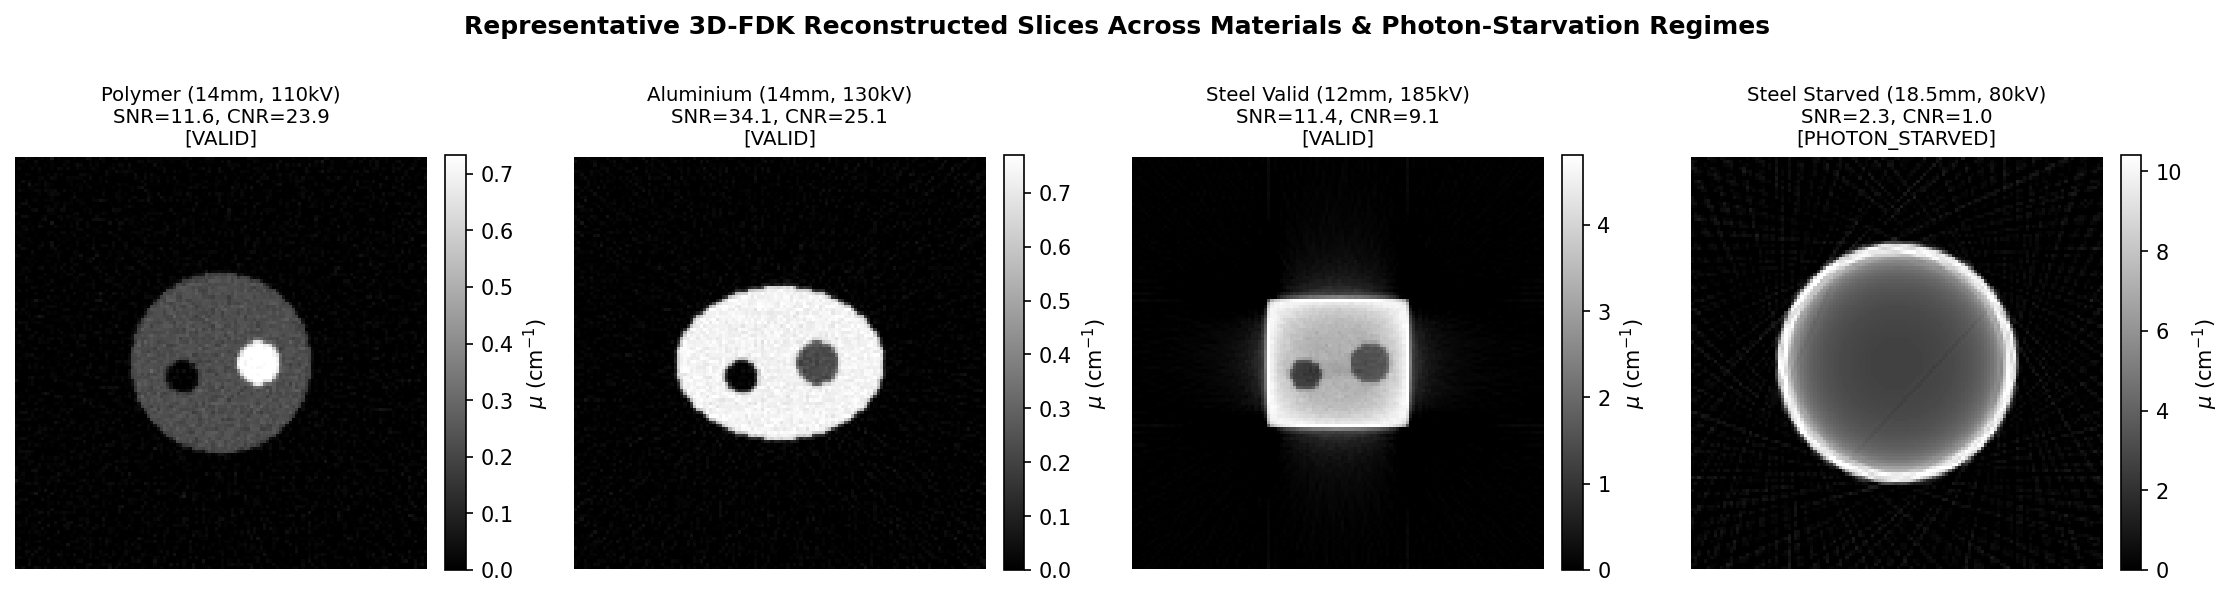

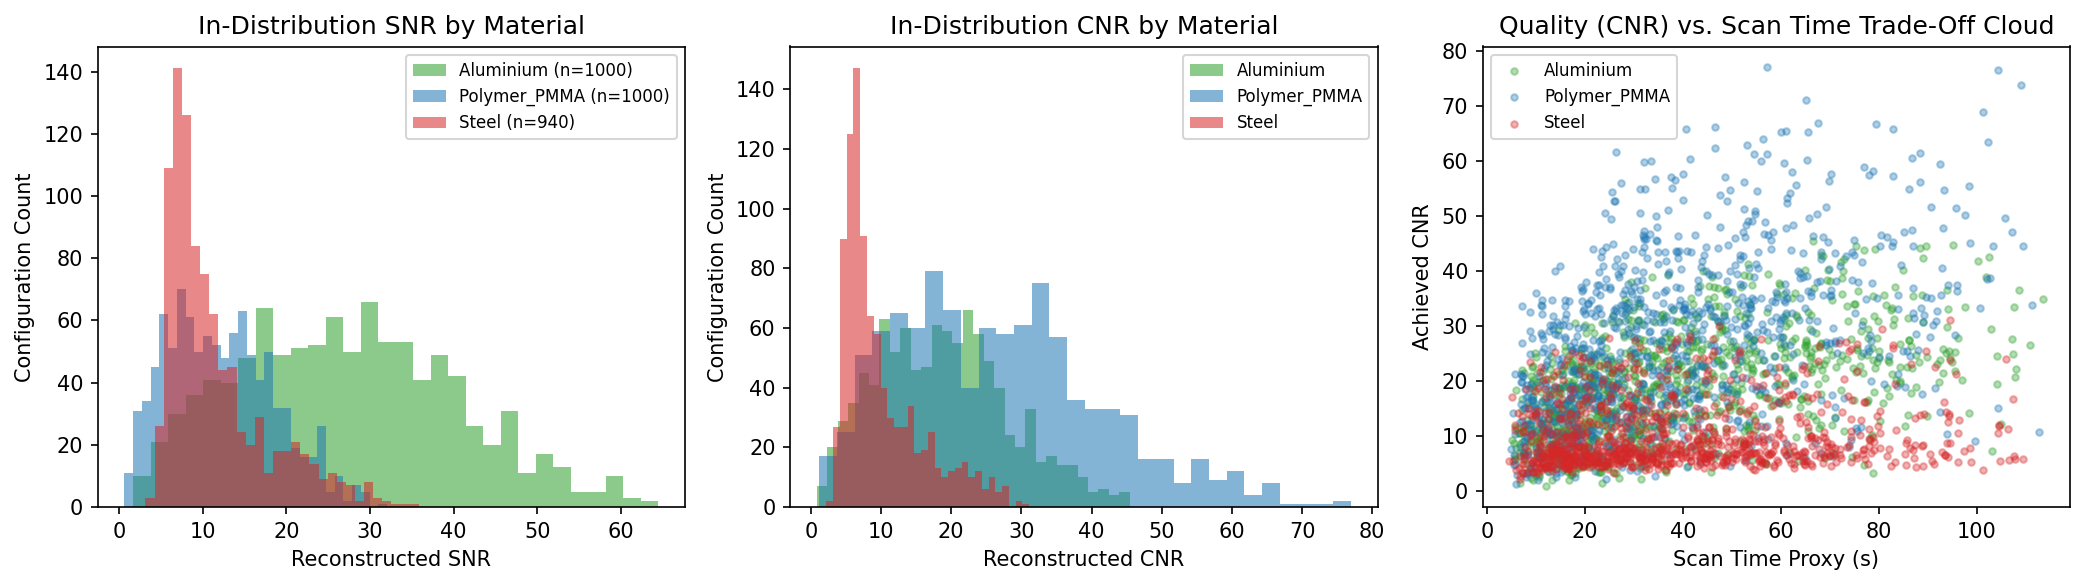


[OK] Saved Figure 1 -> Figures\fig01_representative_reconstructions.png
[OK] Saved Figure 2 -> Figures\fig02_dataset_distributions.png
STAGE 2 COMPLETE.


In [4]:
# ==============================================================================
# STAGE 2: FULL LHS IN-DISTRIBUTION SWEEP, EXTRAPOLATION SWEEP, 
#          STRATIFIED 70/15/15 SPLIT, .NPY SLICES & 10-POINT QUALITY REPORT
# ==============================================================================
import sys
import time
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name != "cws_project":
    PROJECT_ROOT = Path.home() / "Desktop" / "cws_project"

sys.path.insert(0, str(PROJECT_ROOT / "Code"))
import ct_simulator

nist_df = ct_simulator.load_nist_table(PROJECT_ROOT)

# ------------------------------------------------------------------------------
# 1. Build Stratified Latin Hypercube Design for In-Distribution (3,150 rows)
#    (1,000 Polymer_PMMA, 1,000 Aluminium, 1,150 Steel to ensure balanced VALID counts)
# ------------------------------------------------------------------------------
in_dist_specs = [
    ("Polymer_PMMA", 1000, 10001),
    ("Aluminium",    1000, 20002),
    ("Steel",        1150, 30003),
]
geometries = ["cylinder", "ellipse", "block"]

design_in_dist = []
cid = 1
for mat_name, n_mat, seed_val in in_dist_specs:
    sampler = qmc.LatinHypercube(d=6, seed=seed_val)
    U = sampler.random(n=n_mat)
    for i in range(n_mat):
        u = U[i]
        geom = geometries[i % 3]
        design_in_dist.append({
            "config_id": cid,
            "subset_type": "IN_DISTRIBUTION",
            "extrap_regime": "IN_DIST",
            "material": mat_name,
            "geometry_type": geom,
            "sample_size_mm": 5.0 + u[0] * 15.0,          # [5.0, 20.0] mm
            "density_scale":  0.92 + u[1] * 0.16,         # [0.92, 1.08]
            "tube_voltage_kv": 75.0 + u[2] * 145.0,       # [75.0, 220.0] kV
            "mas_per_proj":   0.10 + u[3] * 1.40,         # [0.10, 1.50] mAs/proj
            "n_projections":  int(np.round(60 + u[4] * 300)), # [60, 360] views
            "filter_cu_mm":   u[5] * 2.0,                 # [0.0, 2.0] mm Cu
            "rng_seed":       50000 + cid,
        })
        cid += 1

# ------------------------------------------------------------------------------
# 2. Build Dedicated Extrapolation Design (450 rows: 150 per material)
#    Probing 3 distinct out-of-distribution regimes outside training ranges
# ------------------------------------------------------------------------------
extrap_specs = [
    ("Polymer_PMMA", 150, 40004),
    ("Aluminium",    150, 50005),
    ("Steel",        150, 60006),
]

design_extrap = []
for mat_name, n_mat, seed_val in extrap_specs:
    sampler = qmc.LatinHypercube(d=6, seed=seed_val)
    U = sampler.random(n=n_mat)
    for i in range(n_mat):
        u = U[i]
        geom = geometries[i % 3]
        regime_idx = i % 3
        if regime_idx == 0:
            # E1: Thicker samples (20.5 - 26.0 mm) outside training [5, 20] mm
            regime_label = "E1_THICK_SAMPLE"
            sz_mm   = 20.5 + u[0] * 5.5
            dens_sc = 0.92 + u[1] * 0.16
            kv      = 90.0 + u[2] * 130.0
            mas     = 0.20 + u[3] * 1.30
            n_proj  = int(np.round(80 + u[4] * 280))
            f_cu    = u[5] * 2.0
        elif regime_idx == 1:
            # E2: Low kV (55 - 74 kV) or Heavy Cu Filter (2.05 - 3.0 mm)
            regime_label = "E2_LOW_KV_HEAVY_FILTER"
            sz_mm   = 6.0 + u[0] * 12.0
            dens_sc = 0.92 + u[1] * 0.16
            kv      = 55.0 + u[2] * 19.0 if (i % 2 == 0) else (85.0 + u[2] * 135.0)
            mas     = 0.20 + u[3] * 1.30
            n_proj  = int(np.round(80 + u[4] * 280))
            f_cu    = (0.2 + u[5] * 1.8) if (i % 2 == 0) else (2.05 + u[5] * 0.95)
        else:
            # E3: Extreme projection count (<60 or >360) and High Exposure (1.55 - 2.20 mAs)
            regime_label = "E3_EXTREME_PROJ_MAS"
            sz_mm   = 6.0 + u[0] * 14.0
            dens_sc = 0.92 + u[1] * 0.16
            kv      = 85.0 + u[2] * 135.0
            mas     = 1.55 + u[3] * 0.65
            n_proj  = int(np.round(36 + u[4] * 20)) if (i % 2 == 0) else int(np.round(368 + u[4] * 72))
            f_cu    = u[5] * 2.0
            
        design_extrap.append({
            "config_id": cid,
            "subset_type": "EXTRAPOLATION",
            "extrap_regime": regime_label,
            "material": mat_name,
            "geometry_type": geom,
            "sample_size_mm": sz_mm,
            "density_scale":  dens_sc,
            "tube_voltage_kv": kv,
            "mas_per_proj":   mas,
            "n_projections":  n_proj,
            "filter_cu_mm":   f_cu,
            "rng_seed":       50000 + cid,
        })
        cid += 1

all_designs = design_in_dist + design_extrap
total_to_run = len(all_designs)
print("=" * 80)
print(f"STAGE 2 SWEEP DESIGN READY | Total Configurations: {total_to_run} (3,150 In-Dist + 450 Extrap)")
print("=" * 80)

# ------------------------------------------------------------------------------
# 3. Execute Simulation Sweep with Checkpointing & Representative Slice Saving
# ------------------------------------------------------------------------------
checkpoint_csv = PROJECT_ROOT / "Data" / "Raw_Sweep" / "checkpoint_all_simulations.csv"
slices_dir = PROJECT_ROOT / "Data" / "Slices"

completed_records = []
completed_ids = set()
if checkpoint_csv.exists():
    existing_df = pd.read_csv(checkpoint_csv)
    if len(existing_df) > 0:
        completed_records = existing_df.to_dict("records")
        completed_ids = set(existing_df["config_id"].astype(int).tolist())
        print(f"[RESUME] Loaded {len(completed_ids)} already-completed configurations from checkpoint.")

# Select 54 representative configurations to save as .npy slices (covering materials, geometries, regimes)
rep_slice_ids = set()
for m_idx in range(3):
    base_offset = m_idx * 1000 if m_idx < 2 else 2000
    for g_idx in range(3):
        # Save 5 slices per (material, geometry) in-distribution + 1 in extrapolation
        for k in range(5):
            rep_slice_ids.add(base_offset + g_idx + k * 90 + 1)
for e_idx in range(9):
    rep_slice_ids.add(3151 + e_idx * 45)

slice_manifest_rows = []
t_sweep_start = time.perf_counter()

for idx, cfg in enumerate(all_designs, 1):
    c_id = cfg["config_id"]
    if c_id in completed_ids:
        continue
        
    save_this_slice = (c_id in rep_slice_ids)
    out = ct_simulator.simulate_single_configuration(
        config_id=c_id,
        material=cfg["material"],
        geometry_type=cfg["geometry_type"],
        sample_size_mm=cfg["sample_size_mm"],
        density_scale=cfg["density_scale"],
        tube_voltage_kv=cfg["tube_voltage_kv"],
        mas_per_proj=cfg["mas_per_proj"],
        n_projections=cfg["n_projections"],
        filter_cu_mm=cfg["filter_cu_mm"],
        nist_df=nist_df,
        rng_seed=cfg["rng_seed"],
        return_slice=save_this_slice,
    )
    if save_this_slice:
        rec, recon_arr, _ = out
        slice_fname = f"slice_cid{c_id:04d}_{cfg['material']}_{cfg['geometry_type']}_{rec['sim_status']}.npy"
        np.save(slices_dir / slice_fname, recon_arr.astype(np.float32))
        rec["saved_slice_file"] = slice_fname
        slice_manifest_rows.append({
            "config_id": c_id,
            "slice_file": slice_fname,
            "subset_type": cfg["subset_type"],
            "material": cfg["material"],
            "geometry_type": cfg["geometry_type"],
            "sim_status": rec["sim_status"],
            "snr": rec["snr"],
            "cnr": rec["cnr"],
            "tube_voltage_kv": cfg["tube_voltage_kv"],
            "mas_per_proj": cfg["mas_per_proj"],
            "n_projections": cfg["n_projections"],
        })
    else:
        rec = out
        rec["saved_slice_file"] = ""
        
    rec["subset_type"] = cfg["subset_type"]
    rec["extrap_regime"] = cfg["extrap_regime"]
    completed_records.append(rec)
    
    # Checkpoint to disk every 450 configurations
    if idx % 450 == 0 or idx == total_to_run:
        elapsed = time.perf_counter() - t_sweep_start
        rate = idx / max(elapsed, 1e-6)
        rem_s = (total_to_run - idx) / max(rate, 1e-6)
        pd.DataFrame(completed_records).to_csv(checkpoint_csv, index=False)
        print(f"  [Progress {idx:4d}/{total_to_run}] Elapsed: {elapsed:5.1f}s | Speed: {rate:5.1f} sims/s | Est. Remaining: {rem_s:4.1f}s | Checkpoint saved.")

# Save slice manifest
if slice_manifest_rows:
    pd.DataFrame(slice_manifest_rows).to_csv(slices_dir / "slices_manifest.csv", index=False)

# ------------------------------------------------------------------------------
# 4. Separate Master Tables, Filter Valid Configs, and Perform 70/15/15 Split
# ------------------------------------------------------------------------------
master_df = pd.DataFrame(completed_records)

in_dist_all_df = master_df[master_df["subset_type"] == "IN_DISTRIBUTION"].copy()
extrap_all_df  = master_df[master_df["subset_type"] == "EXTRAPOLATION"].copy()

in_dist_all_df.to_csv(PROJECT_ROOT / "Data" / "Raw_Sweep" / "in_distribution_master_all.csv", index=False)
extrap_all_df.to_csv(PROJECT_ROOT / "Data" / "Raw_Sweep" / "extrapolation_master_all.csv", index=False)

# Retain physically VALID configurations for surrogate training/testing, while keeping starvation logs
in_dist_valid_df = in_dist_all_df[in_dist_all_df["sim_status"] == "VALID"].reset_index(drop=True)
extrap_valid_df  = extrap_all_df[extrap_all_df["sim_status"] == "VALID"].reset_index(drop=True)

# Stratified 70 / 15 / 15 split by (material, geometry_type)
strata_col = in_dist_valid_df["material"] + "_" + in_dist_valid_df["geometry_type"]
train_df, temp_df = train_test_split(
    in_dist_valid_df, test_size=0.30, random_state=2026, stratify=strata_col
)
temp_strata = temp_df["material"] + "_" + temp_df["geometry_type"]
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=2026, stratify=temp_strata
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

# Save split datasets to their exact designated folders
train_path  = PROJECT_ROOT / "Data" / "Training" / "train_data.csv"
val_path    = PROJECT_ROOT / "Data" / "Validation" / "val_data.csv"
test_path   = PROJECT_ROOT / "Data" / "Testing" / "test_data.csv"
extrap_path = PROJECT_ROOT / "Data" / "Extrapolation" / "extrapolation_test_data.csv"

train_df.to_csv(train_path, index=False)
val_df.to_csv(val_path, index=False)
test_df.to_csv(test_path, index=False)
extrap_valid_df.to_csv(extrap_path, index=False)

# ------------------------------------------------------------------------------
# 5. Generate Complete 10-Point Dataset Quality Report
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("10-POINT DATASET QUALITY REPORT")
print("=" * 80)

print("\n[1] ATTEMPTED vs. RETAINED CONFIGURATIONS:")
print(f"  In-Distribution Attempted : {len(in_dist_all_df)} | VALID Retained: {len(in_dist_valid_df)} ({100*len(in_dist_valid_df)/len(in_dist_all_df):.1f}%)")
print(f"  Extrapolation Attempted   : {len(extrap_all_df)}  | VALID Retained: {len(extrap_valid_df)} ({100*len(extrap_valid_df)/len(extrap_all_df):.1f}%)")

print("\n[2] IN-DISTRIBUTION SPLIT COUNTS (70 / 15 / 15):")
print(f"  Training Set   : {len(train_df):4d} rows ({100*len(train_df)/len(in_dist_valid_df):.1f}%) -> {train_path.relative_to(PROJECT_ROOT)}")
print(f"  Validation Set : {len(val_df):4d} rows ({100*len(val_df)/len(in_dist_valid_df):.1f}%) -> {val_path.relative_to(PROJECT_ROOT)}")
print(f"  Testing Set    : {len(test_df):4d} rows ({100*len(test_df)/len(in_dist_valid_df):.1f}%) -> {test_path.relative_to(PROJECT_ROOT)}")
overlap_check = len(set(train_df["config_id"]).intersection(set(val_df["config_id"])).union(set(train_df["config_id"]).intersection(set(test_df["config_id"]))))
print(f"  Data Leakage Overlap Check (Train/Val/Test config_id intersection): {overlap_check} (MUST BE 0)")

print("\n[3] EXTRAPOLATION DATASET BREAKDOWN BY REGIME:")
print(pd.crosstab(extrap_all_df["extrap_regime"], extrap_all_df["sim_status"], margins=True))

print("\n[4] IN-DISTRIBUTION MATERIAL BALANCE (ATTEMPTED vs. VALID):")
print(pd.crosstab(in_dist_all_df["material"], in_dist_all_df["sim_status"], margins=True))

print("\n[5] IN-DISTRIBUTION GEOMETRY BALANCE (VALID):")
print(pd.crosstab(in_dist_valid_df["geometry_type"], in_dist_valid_df["material"], margins=True))

print("\n[6 & 8] PARAMETER & IMAGE-QUALITY DISTRIBUTIONS (VALID IN-DISTRIBUTION SET):")
summary_cols = [
    "sample_size_mm", "bulk_density_g_cm3", "tube_voltage_kv", "mas_per_proj",
    "n_projections", "filter_cu_mm", "snr", "cnr", "edge_fwhm_mm", "cupping_index_pct", "scan_time_s"
]
print(in_dist_valid_df[summary_cols].describe(percentiles=[0.05, 0.5, 0.95]).T[["count", "mean", "std", "min", "5%", "50%", "95%", "max"]].to_string(float_format=lambda x: f"{x:.3f}"))

print("\n[7] PHOTON-STARVATION PHYSICS ANALYSIS (STEEL IN-DISTRIBUTION):")
steel_all = in_dist_all_df[in_dist_all_df["material"] == "Steel"]
for st_label, grp in steel_all.groupby("sim_status"):
    print(f"  Steel [{st_label:<14}] (n={len(grp):4d}): Mean size={grp['sample_size_mm'].mean():.2f} mm, Mean kV={grp['tube_voltage_kv'].mean():.1f} kV, Mean mAs={grp['mas_per_proj'].mean():.2f}, Median MinPhotons={grp['min_transmitted_photons'].median():.2f}")

print("\n[9] SAVED REPRESENTATIVE .NPY SLICES:")
npy_saved = list(slices_dir.glob("*.npy"))
print(f"  Total .npy slices saved in Data/Slices/: {len(npy_saved)}")

print("\n[10] INTEGRITY CHECKS (DUPLICATES, MISSING VALUES, PHYSICAL BOUNDS):")
n_dups = int(in_dist_valid_df.duplicated(subset=["material", "geometry_type", "sample_size_mm", "tube_voltage_kv", "mas_per_proj", "n_projections"]).sum())
n_nans = int(in_dist_valid_df[summary_cols].isna().sum().sum())
n_neg_qual = int(((in_dist_valid_df["snr"] <= 0) | (in_dist_valid_df["cnr"] <= 0) | (in_dist_valid_df["scan_time_s"] <= 0)).sum())
print(f"  Duplicate parameter rows : {n_dups}")
print(f"  Missing/NaN values       : {n_nans}")
print(f"  Invalid quality (<=0)    : {n_neg_qual}")

# ------------------------------------------------------------------------------
# 6. Save Publication-Ready Diagnostic Figures (Fig 1: Slices, Fig 2: Distributions)
# ------------------------------------------------------------------------------
fig1, axes1 = plt.subplots(1, 4, figsize=(15, 4.0), dpi=150)
demo_cases = [
    ("Polymer_PMMA", "cylinder", 14.0, 110.0, 0.80, 180, 0.5, "Polymer (14mm, 110kV)"),
    ("Aluminium",    "ellipse",  14.0, 130.0, 0.80, 180, 0.5, "Aluminium (14mm, 130kV)"),
    ("Steel",        "block",    12.0, 185.0, 1.10, 240, 1.0, "Steel Valid (12mm, 185kV)"),
    ("Steel",        "cylinder", 18.5,  80.0, 0.15,  90, 0.0, "Steel Starved (18.5mm, 80kV)"),
]
for ax, (m, g, sz, kv, mas, npj, fcu, title_str) in zip(axes1, demo_cases):
    r_info, sl_img, _ = ct_simulator.simulate_single_configuration(
        9999, m, g, sz, 1.0, kv, mas, npj, fcu, nist_df, rng_seed=42, return_slice=True
    )
    im = ax.imshow(sl_img, cmap="gray", vmin=0.0, vmax=np.percentile(sl_img, 99.5))
    ax.set_title(f"{title_str}\nSNR={r_info['snr']:.1f}, CNR={r_info['cnr']:.1f}\n[{r_info['sim_status']}]", fontsize=9.5)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=r"$\mu$ ($\mathrm{cm}^{-1}$)")

plt.suptitle("Representative 3D-FDK Reconstructed Slices Across Materials & Photon-Starvation Regimes", fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
fig1_path = PROJECT_ROOT / "Figures" / "fig01_representative_reconstructions.png"
fig1.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()

fig2, axes2 = plt.subplots(1, 3, figsize=(14, 4.0), dpi=150)
colors = {"Polymer_PMMA": "#1f77b4", "Aluminium": "#2ca02c", "Steel": "#d62728"}

for mat_name, grp in in_dist_valid_df.groupby("material"):
    axes2[0].hist(grp["snr"], bins=30, alpha=0.55, label=f"{mat_name} (n={len(grp)})", color=colors[mat_name])
    axes2[1].hist(grp["cnr"], bins=30, alpha=0.55, label=mat_name, color=colors[mat_name])
    axes2[2].scatter(grp["scan_time_s"], grp["cnr"], s=10, alpha=0.35, label=mat_name, color=colors[mat_name])

axes2[0].set_xlabel("Reconstructed SNR")
axes2[0].set_ylabel("Configuration Count")
axes2[0].set_title("In-Distribution SNR by Material")
axes2[0].legend(fontsize=8)

axes2[1].set_xlabel("Reconstructed CNR")
axes2[1].set_ylabel("Configuration Count")
axes2[1].set_title("In-Distribution CNR by Material")
axes2[1].legend(fontsize=8)

axes2[2].set_xlabel("Scan Time Proxy (s)")
axes2[2].set_ylabel("Achieved CNR")
axes2[2].set_title("Quality (CNR) vs. Scan Time Trade-Off Cloud")
axes2[2].legend(fontsize=8)

plt.tight_layout()
fig2_path = PROJECT_ROOT / "Figures" / "fig02_dataset_distributions.png"
fig2.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n[OK] Saved Figure 1 -> {fig1_path.relative_to(PROJECT_ROOT)}")
print(f"[OK] Saved Figure 2 -> {fig2_path.relative_to(PROJECT_ROOT)}")
print("STAGE 2 COMPLETE.")

[OK] Patched roi_center/roi_perim fallback in ct_simulator.py for 5mm samples.
Loaded Splits | Train: 2058, Val: 441, Test: 441, Extrap: 397
Total NaNs across all splits: 3284

TRAINING SURROGATES & RUNNING 5-FOLD CROSS-VALIDATION (ON TRAINING SET)
  [XGBoost        ] 5-Fold CV CNR R2: 0.9696 +/- 0.0020 | Fit Time:  5.26s
  [RandomForest   ] 5-Fold CV CNR R2: 0.8395 +/- 0.0287 | Fit Time:  3.21s
  [MLP_64_64_32   ] 5-Fold CV CNR R2: 0.9771 +/- 0.0028 | Fit Time:  8.70s
  [GaussianProcess] 5-Fold CV CNR R2: 0.9794 +/- 0.0018 | Fit Time: 277.24s

[OK] Saved all 4 trained surrogates & scaler to: Models\trained_surrogates_bundle.pkl

EXPERIMENT 1 & 3: SURROGATE PERFORMANCE SUMMARY (SNR & CNR)
          model         split  snr_MAE  snr_RMSE  snr_R2  cnr_MAE  cnr_RMSE  cnr_R2  scan_time_s_R2
        XGBoost    Validation   1.3912    2.0265  0.9677   1.4907    2.1294  0.9713          0.9982
        XGBoost   InDist_Test   1.3010    1.9289  0.9734   1.5946    2.2714  0.9647          0.9984
  

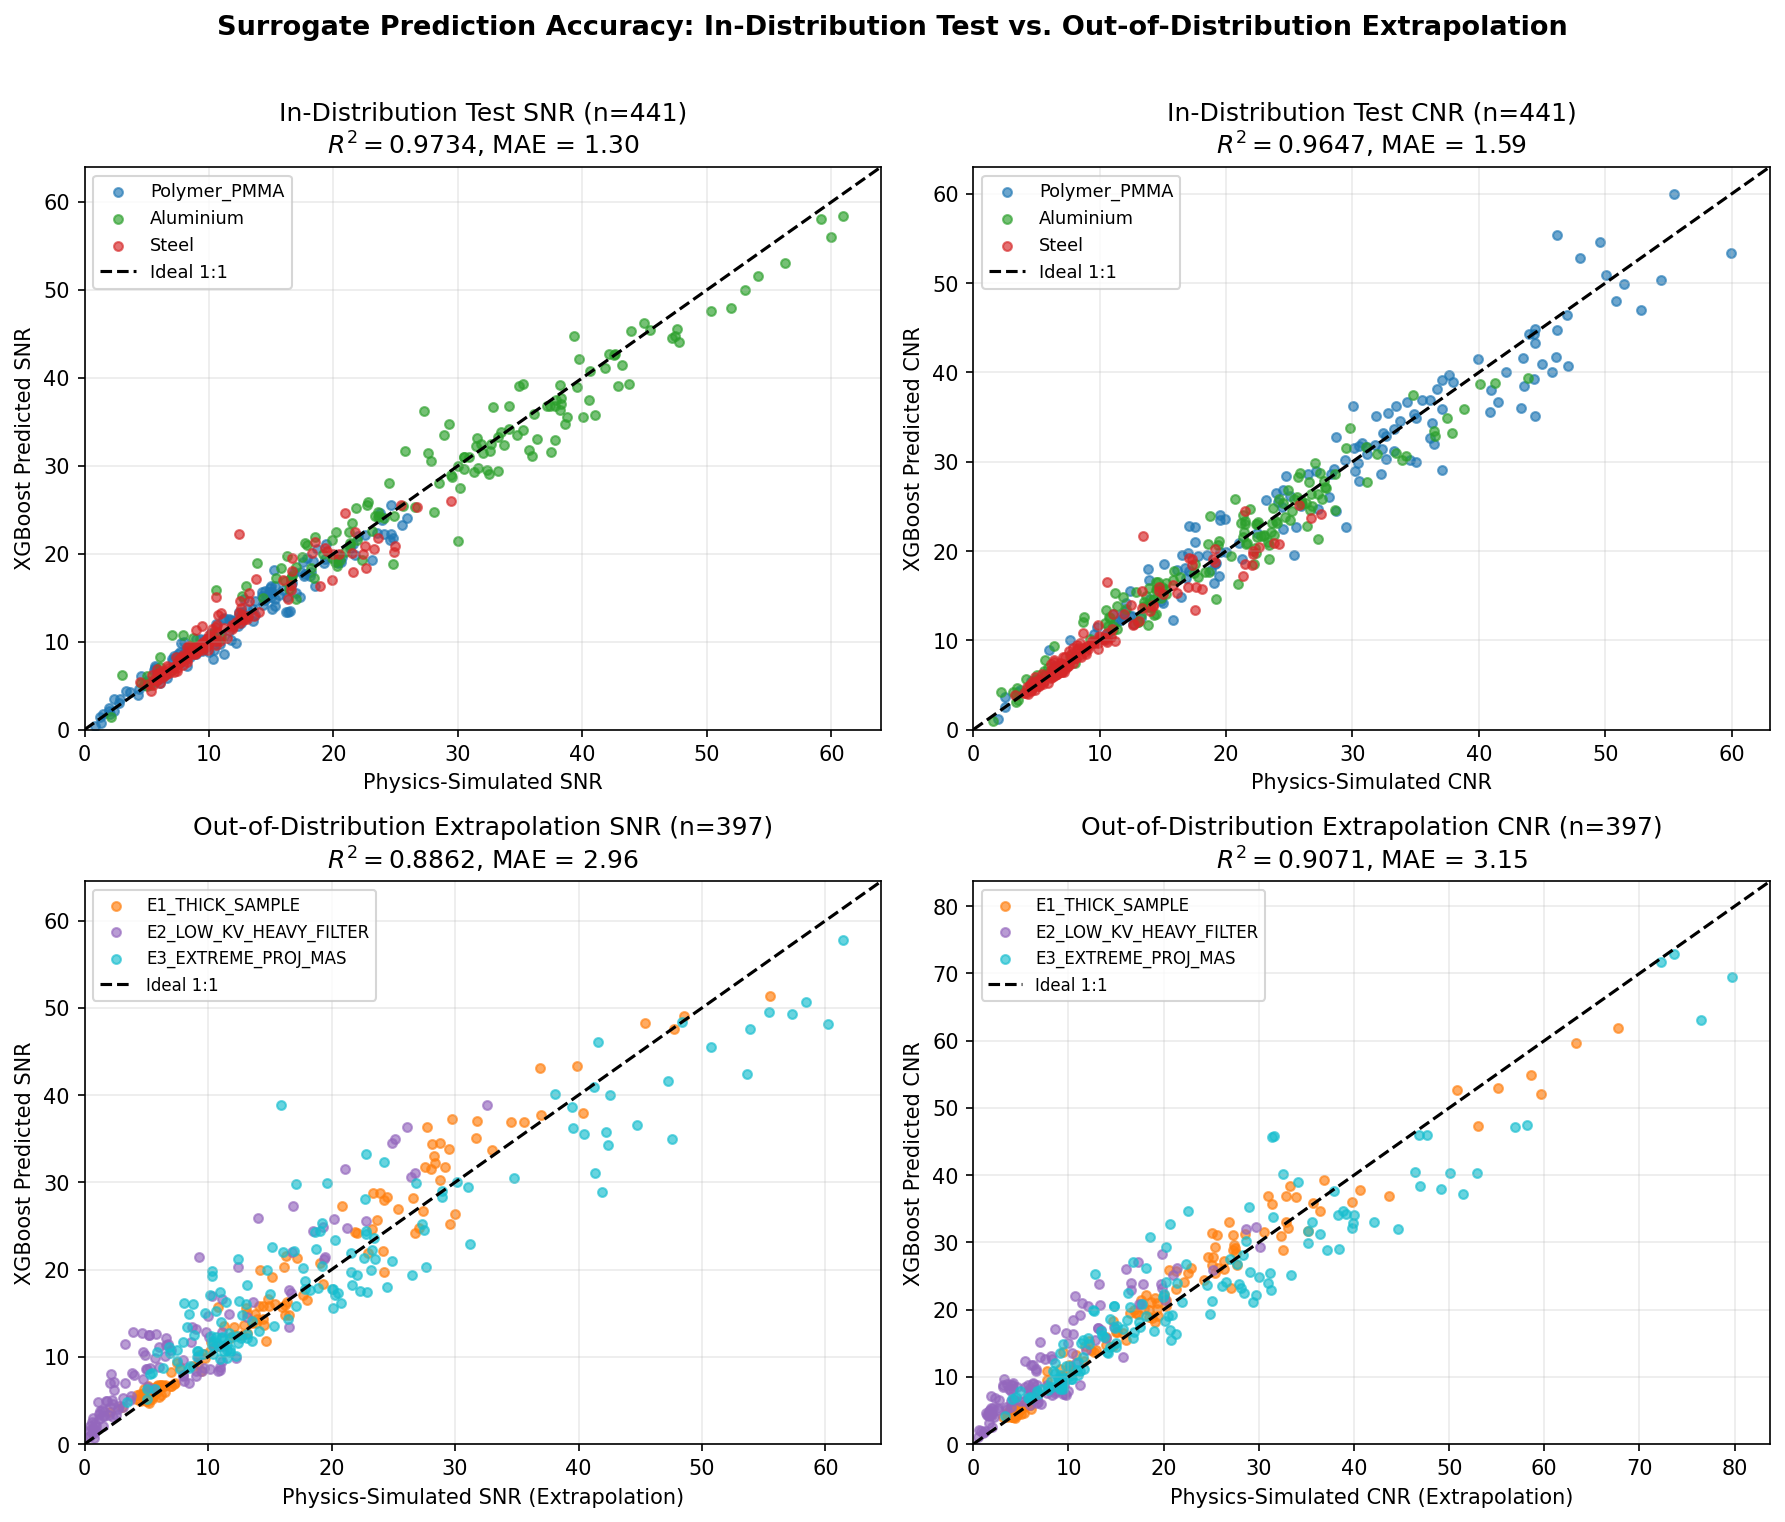

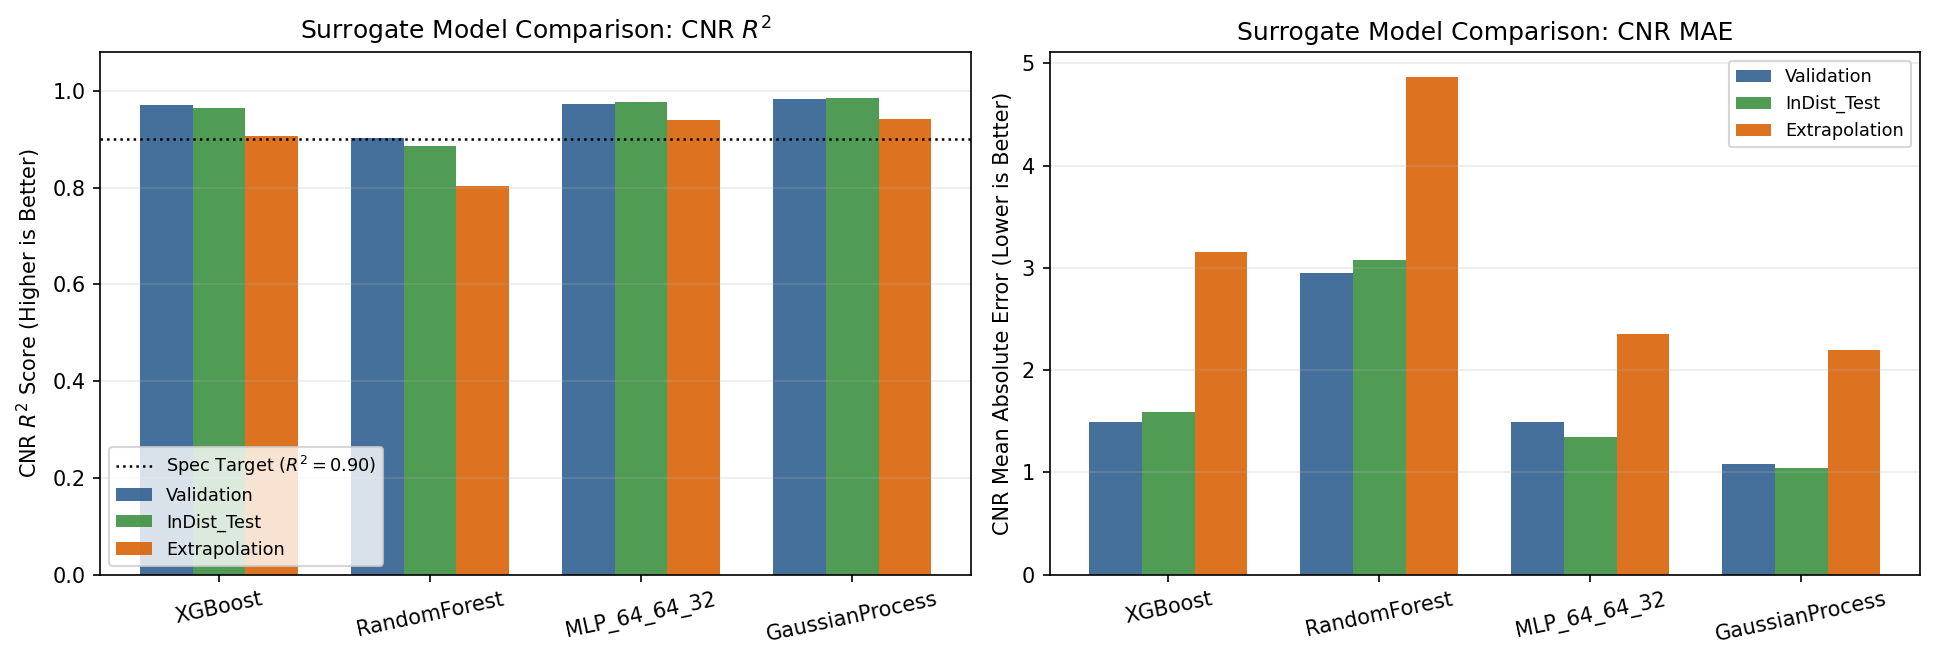

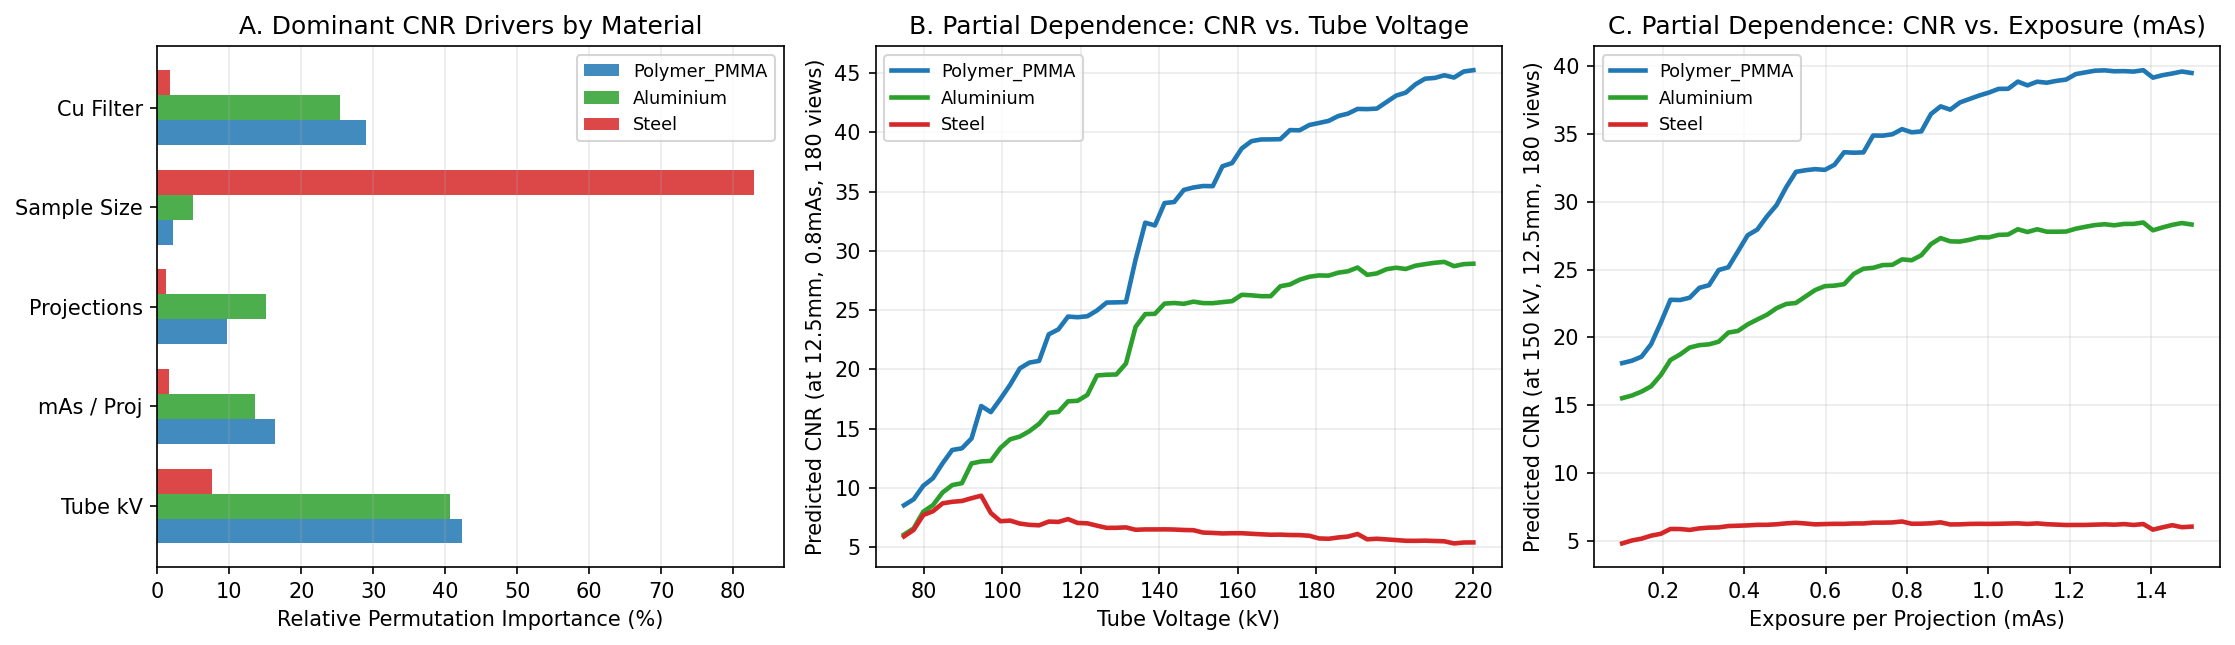


[OK] Saved Figure 3 -> Figures\fig03_surrogate_parity_scatter.png
[OK] Saved Figure 4 -> Figures\fig04_model_comparison_and_extrapolation.png
[OK] Saved Figure 5 -> Figures\fig05_feature_sensitivity_by_material.png
STAGE 3 COMPLETE.


In [5]:
# ==============================================================================
# STAGE 3: SURROGATE TRAINING (RF, XGBOOST, MLP, GP), 5-FOLD CV,
#          EXTRAPOLATION PROBING (EXP 1 & 3) & SENSITIVITY ANALYSIS (EXP 4)
# ==============================================================================
import sys
import time
import pickle
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name != "cws_project":
    PROJECT_ROOT = Path.home() / "Desktop" / "cws_project"

sys.path.insert(0, str(PROJECT_ROOT / "Code"))
import importlib
import ct_simulator

# ------------------------------------------------------------------------------
# 1. Patch ct_simulator.py roi_center fallback for tiny 5mm samples & clean NaNs
# ------------------------------------------------------------------------------
sim_path = PROJECT_ROOT / "Code" / "ct_simulator.py"
sim_text = sim_path.read_text(encoding="utf-8")
old_snippet = """    R_radial = np.sqrt(X**2 + Y**2)
    roi_center = matrix_mask & (R_radial <= 0.35 * radius_mm)
    roi_perim = matrix_mask & (R_radial >= 0.65 * radius_mm) & (R_radial <= 0.88 * radius_mm)"""

new_snippet = """    R_radial = np.sqrt(X**2 + Y**2)
    roi_center = matrix_mask & (R_radial <= 0.35 * radius_mm)
    if np.sum(roi_center) < 5:
        r_mat = R_radial[matrix_mask]
        roi_center = matrix_mask & (R_radial <= np.percentile(r_mat, 25.0))
    roi_perim = matrix_mask & (R_radial >= 0.65 * radius_mm) & (R_radial <= 0.88 * radius_mm)
    if np.sum(roi_perim) < 5:
        r_mat = R_radial[matrix_mask]
        roi_perim = matrix_mask & (R_radial >= np.percentile(r_mat, 70.0))"""

if old_snippet in sim_text:
    sim_path.write_text(sim_text.replace(old_snippet, new_snippet), encoding="utf-8")
    importlib.reload(ct_simulator)
    print("[OK] Patched roi_center/roi_perim fallback in ct_simulator.py for 5mm samples.")

for csv_rel in [
    "Data/Raw_Sweep/checkpoint_all_simulations.csv",
    "Data/Raw_Sweep/in_distribution_master_all.csv",
    "Data/Raw_Sweep/extrapolation_master_all.csv",
    "Data/Training/train_data.csv",
    "Data/Validation/val_data.csv",
    "Data/Testing/test_data.csv",
    "Data/Extrapolation/extrapolation_test_data.csv",
]:
    p = PROJECT_ROOT / csv_rel
    if p.exists():
        df_tmp = pd.read_csv(p)
        if df_tmp["cupping_index_pct"].isna().sum() > 0:
            df_tmp["cupping_index_pct"] = df_tmp.groupby("material")["cupping_index_pct"].transform(
                lambda s: s.fillna(s.median())
            )
            df_tmp.to_csv(p, index=False)

# Load clean splits
train_df  = pd.read_csv(PROJECT_ROOT / "Data" / "Training" / "train_data.csv")
val_df    = pd.read_csv(PROJECT_ROOT / "Data" / "Validation" / "val_data.csv")
test_df   = pd.read_csv(PROJECT_ROOT / "Data" / "Testing" / "test_data.csv")
extrap_df = pd.read_csv(PROJECT_ROOT / "Data" / "Extrapolation" / "extrapolation_test_data.csv")

print(f"Loaded Splits | Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}, Extrap: {len(extrap_df)}")
print(f"Total NaNs across all splits: {int(train_df.isna().sum().sum() + val_df.isna().sum().sum() + test_df.isna().sum().sum() + extrap_df.isna().sum().sum())}")

# ------------------------------------------------------------------------------
# 2. Feature & Target Specification + Zero-Leakage Feature Scaling
# ------------------------------------------------------------------------------
# 8 core input parameters (4 sample features + 4 acquisition parameters)
FEATURE_COLS = [
    "material_code",       # Sample property 1 (0=Polymer, 1=Al, 2=Steel)
    "geometry_code",       # Sample property 2 (0=cylinder, 1=ellipse, 2=block)
    "sample_size_mm",      # Sample property 3 (thickness / diameter in mm)
    "bulk_density_g_cm3",  # Sample property 4 (physical density in g/cm^3)
    "tube_voltage_kv",     # Acquisition param 1 (kV)
    "mas_per_proj",        # Acquisition param 2 (exposure mAs per projection)
    "n_projections",       # Acquisition param 3 (number of projection views)
    "filter_cu_mm",        # Acquisition param 4 (Cu filtration thickness in mm)
]

# Primary targets: SNR and CNR (jointly predicted), plus Resolution Proxy and Scan-Time Proxy
TARGET_COLS = ["snr", "cnr", "edge_fwhm_mm", "scan_time_s"]

X_train_raw  = train_df[FEATURE_COLS].values
X_val_raw    = val_df[FEATURE_COLS].values
X_test_raw   = test_df[FEATURE_COLS].values
X_extrap_raw = extrap_df[FEATURE_COLS].values

Y_train  = train_df[TARGET_COLS].values
Y_val    = val_df[TARGET_COLS].values
Y_test   = test_df[TARGET_COLS].values
Y_extrap = extrap_df[TARGET_COLS].values

# Fit StandardScaler STRICTLY on Training set
scaler_X = StandardScaler()
X_train_sc  = scaler_X.fit_transform(X_train_raw)
X_val_sc    = scaler_X.transform(X_val_raw)
X_test_sc   = scaler_X.transform(X_test_raw)
X_extrap_sc = scaler_X.transform(X_extrap_raw)

# ------------------------------------------------------------------------------
# 3. Define & Train the 4 Surrogate Models + 5-Fold Cross-Validation on Training
# ------------------------------------------------------------------------------
models = {
    "XGBoost": MultiOutputRegressor(
        XGBRegressor(
            n_estimators=450,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.90,
            reg_lambda=1.5,
            random_state=2026,
            n_jobs=-1,
        )
    ),
    "RandomForest": RandomForestRegressor(
        n_estimators=400,
        max_depth=18,
        min_samples_leaf=2,
        random_state=2026,
        n_jobs=-1,
    ),
    "MLP_64_64_32": MLPRegressor(
        hidden_layer_sizes=(64, 64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-3,
        learning_rate_init=1e-3,
        max_iter=350,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=2026,
    ),
    "GaussianProcess": MultiOutputRegressor(
        GaussianProcessRegressor(
            kernel=ConstantKernel(1.0, (1e-2, 1e3)) * RBF(length_scale=np.ones(len(FEATURE_COLS)), length_scale_bounds=(1e-1, 1e2))
                   + WhiteKernel(noise_level=0.05, noise_level_bounds=(1e-4, 10.0)),
            normalize_y=True,
            n_restarts_optimizer=1,
            random_state=2026,
        )
    ),
}

print("\n" + "=" * 80)
print("TRAINING SURROGATES & RUNNING 5-FOLD CROSS-VALIDATION (ON TRAINING SET)")
print("=" * 80)

kf = KFold(n_splits=5, shuffle=True, random_state=2026)
cv_summary_rows = []
eval_rows = []
trained_models = {}
predictions_store = {}

for name, model in models.items():
    t0 = time.perf_counter()
    # Fast 5-fold CV for CNR R^2 on training set (for GP, use 3-fold on a 1000-row subsample for speed, then fit full)
    if name != "GaussianProcess":
        cnr_estimator = model.estimator if hasattr(model, "estimator") else model
        cv_scores = cross_val_score(cnr_estimator, X_train_sc, Y_train[:, 1], cv=kf, scoring="r2", n_jobs=-1)
        cv_r2_mean, cv_r2_std = float(np.mean(cv_scores)), float(np.std(cv_scores))
    else:
        kf_gp = KFold(n_splits=3, shuffle=True, random_state=2026)
        cv_scores = cross_val_score(model.estimator, X_train_sc[:900], Y_train[:900, 1], cv=kf_gp, scoring="r2", n_jobs=-1)
        cv_r2_mean, cv_r2_std = float(np.mean(cv_scores)), float(np.std(cv_scores))
        
    # Fit on full training dataset
    model.fit(X_train_sc, Y_train)
    train_time_s = time.perf_counter() - t0
    trained_models[name] = model
    
    # Predict across splits
    preds = {
        "Training":      model.predict(X_train_sc),
        "Validation":    model.predict(X_val_sc),
        "InDist_Test":   model.predict(X_test_sc),
        "Extrapolation": model.predict(X_extrap_sc),
    }
    predictions_store[name] = preds
    
    print(f"  [{name:<15}] 5-Fold CV CNR R2: {cv_r2_mean:.4f} +/- {cv_r2_std:.4f} | Fit Time: {train_time_s:5.2f}s")
    
    for split_name, Y_true in [
        ("Training", Y_train),
        ("Validation", Y_val),
        ("InDist_Test", Y_test),
        ("Extrapolation", Y_extrap),
    ]:
        Y_pred = preds[split_name]
        row = {
            "model": name,
            "split": split_name,
            "cv_cnr_r2_mean": cv_r2_mean,
            "cv_cnr_r2_std": cv_r2_std,
            "train_time_s": train_time_s,
        }
        for t_idx, t_col in enumerate(TARGET_COLS):
            yt = Y_true[:, t_idx]
            yp = Y_pred[:, t_idx]
            row[f"{t_col}_MAE"]  = float(mean_absolute_error(yt, yp))
            row[f"{t_col}_RMSE"] = float(root_mean_squared_error(yt, yp))
            row[f"{t_col}_R2"]   = float(r2_score(yt, yp))
        eval_rows.append(row)

eval_df = pd.DataFrame(eval_rows)
eval_csv_path = PROJECT_ROOT / "Docs" / "surrogate_evaluation_metrics.csv"
eval_df.to_csv(eval_csv_path, index=False)

# Save trained models & scaler bundle to Models/
model_bundle = {
    "scaler_X": scaler_X,
    "feature_cols": FEATURE_COLS,
    "target_cols": TARGET_COLS,
    "models": trained_models,
    "train_bounds": {col: (float(train_df[col].min()), float(train_df[col].max())) for col in FEATURE_COLS},
}
bundle_path = PROJECT_ROOT / "Models" / "trained_surrogates_bundle.pkl"
with open(bundle_path, "wb") as f:
    pickle.dump(model_bundle, f)
print(f"\n[OK] Saved all 4 trained surrogates & scaler to: {bundle_path.relative_to(PROJECT_ROOT)}")

# ------------------------------------------------------------------------------
# 4. Print Comprehensive Model Comparison Table (Experiment 1 & Experiment 3)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("EXPERIMENT 1 & 3: SURROGATE PERFORMANCE SUMMARY (SNR & CNR)")
print("=" * 80)
display_cols = ["model", "split", "snr_MAE", "snr_RMSE", "snr_R2", "cnr_MAE", "cnr_RMSE", "cnr_R2", "scan_time_s_R2"]
print(eval_df[eval_df["split"].isin(["Validation", "InDist_Test", "Extrapolation"])][display_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Detailed Extrapolation Breakdown by Regime for Primary Surrogate (XGBoost) & RF
print("\n" + "=" * 80)
print("EXPERIMENT 3 DETAIL: EXTRAPOLATION PERFORMANCE BY OUT-OF-DISTRIBUTION REGIME")
print("=" * 80)
extrap_regime_rows = []
for m_name in ["XGBoost", "RandomForest", "MLP_64_64_32", "GaussianProcess"]:
    Y_pred_ext = predictions_store[m_name]["Extrapolation"]
    for reg_name in ["E1_THICK_SAMPLE", "E2_LOW_KV_HEAVY_FILTER", "E3_EXTREME_PROJ_MAS"]:
        mask = (extrap_df["extrap_regime"] == reg_name).values
        extrap_regime_rows.append({
            "model": m_name,
            "extrap_regime": reg_name,
            "n_samples": int(np.sum(mask)),
            "snr_MAE": float(mean_absolute_error(Y_extrap[mask, 0], Y_pred_ext[mask, 0])),
            "snr_R2":  float(r2_score(Y_extrap[mask, 0], Y_pred_ext[mask, 0])),
            "cnr_MAE": float(mean_absolute_error(Y_extrap[mask, 1], Y_pred_ext[mask, 1])),
            "cnr_RMSE": float(root_mean_squared_error(Y_extrap[mask, 1], Y_pred_ext[mask, 1])),
            "cnr_R2":  float(r2_score(Y_extrap[mask, 1], Y_pred_ext[mask, 1])),
        })
extrap_reg_df = pd.DataFrame(extrap_regime_rows)
extrap_reg_df.to_csv(PROJECT_ROOT / "Docs" / "extrapolation_by_regime.csv", index=False)
print(extrap_reg_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ------------------------------------------------------------------------------
# 5. Experiment 4: Per-Material Sensitivity Analysis (Feature Importance)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("EXPERIMENT 4: PER-MATERIAL ACQUISITION & SAMPLE SENSITIVITY (CNR IMPORTANCE)")
print("=" * 80)

xgb_cnr_est = trained_models["XGBoost"].estimators_[1]  # Estimator index 1 = CNR
acq_and_size_features = ["sample_size_mm", "tube_voltage_kv", "mas_per_proj", "n_projections", "filter_cu_mm", "geometry_code", "bulk_density_g_cm3"]
feat_indices = [FEATURE_COLS.index(c) for c in acq_and_size_features]

sens_rows = []
for mat_name in ["Polymer_PMMA", "Aluminium", "Steel"]:
    m_mask = (test_df["material"] == mat_name).values
    X_sub = X_test_sc[m_mask]
    y_sub = Y_test[m_mask, 1]
    perm = permutation_importance(xgb_cnr_est, X_sub, y_sub, n_repeats=15, random_state=2026, scoring="r2")
    imp_Selected = {FEATURE_COLS[i]: max(float(perm.importances_mean[i]), 0.0) for i in feat_indices}
    total_imp = sum(imp_Selected.values()) + 1e-12
    row_s = {"material": mat_name}
    for k, v in imp_Selected.items():
        row_s[k] = 100.0 * v / total_imp
    sens_rows.append(row_s)

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(PROJECT_ROOT / "Docs" / "material_sensitivity_importance.csv", index=False)
print("Normalized Permutation Feature Importance (%) for Predicting CNR by Material:")
print(sens_df.to_string(index=False, float_format=lambda x: f"{x:6.2f}%"))

# ------------------------------------------------------------------------------
# 6. Generate Publication-Ready Figures (Fig 3, Fig 4, Fig 5)
# ------------------------------------------------------------------------------
# FIGURE 3: Predicted vs. Simulated Parity Scatter Plots (XGBoost & Random Forest)
fig3, axes3 = plt.subplots(2, 2, figsize=(12, 10), dpi=150)
colors_mat = {"Polymer_PMMA": "#1f77b4", "Aluminium": "#2ca02c", "Steel": "#d62728"}

for col_idx, (t_idx, t_label) in enumerate([(0, "SNR"), (1, "CNR")]):
    # Top row: In-Distribution Test Set (XGBoost)
    ax_in = axes3[0, col_idx]
    yt_in = Y_test[:, t_idx]
    yp_in = predictions_store["XGBoost"]["InDist_Test"][:, t_idx]
    for mat_name in ["Polymer_PMMA", "Aluminium", "Steel"]:
        m_mask = (test_df["material"] == mat_name).values
        ax_in.scatter(yt_in[m_mask], yp_in[m_mask], s=18, alpha=0.65, color=colors_mat[mat_name], label=mat_name)
    lims = [0, max(yt_in.max(), yp_in.max()) * 1.05]
    ax_in.plot(lims, lims, "k--", lw=1.5, label="Ideal 1:1")
    r2_in = r2_score(yt_in, yp_in)
    mae_in = mean_absolute_error(yt_in, yp_in)
    ax_in.set_xlim(lims); ax_in.set_ylim(lims)
    ax_in.set_xlabel(f"Physics-Simulated {t_label}")
    ax_in.set_ylabel(f"XGBoost Predicted {t_label}")
    ax_in.set_title(f"In-Distribution Test {t_label} (n=441)\n$R^2 = {r2_in:.4f}$, MAE = {mae_in:.2f}")
    ax_in.legend(fontsize=8.5)
    ax_in.grid(True, alpha=0.25)

    # Bottom row: Out-of-Distribution Extrapolation Test Set (XGBoost)
    ax_ex = axes3[1, col_idx]
    yt_ex = Y_extrap[:, t_idx]
    yp_ex = predictions_store["XGBoost"]["Extrapolation"][:, t_idx]
    reg_colors = {"E1_THICK_SAMPLE": "#ff7f0e", "E2_LOW_KV_HEAVY_FILTER": "#9467bd", "E3_EXTREME_PROJ_MAS": "#17becf"}
    for reg_name, r_col in reg_colors.items():
        r_mask = (extrap_df["extrap_regime"] == reg_name).values
        ax_ex.scatter(yt_ex[r_mask], yp_ex[r_mask], s=18, alpha=0.65, color=r_col, label=reg_name)
    lims_ex = [0, max(yt_ex.max(), yp_ex.max()) * 1.05]
    ax_ex.plot(lims_ex, lims_ex, "k--", lw=1.5, label="Ideal 1:1")
    r2_ex = r2_score(yt_ex, yp_ex)
    mae_ex = mean_absolute_error(yt_ex, yp_ex)
    ax_ex.set_xlim(lims_ex); ax_ex.set_ylim(lims_ex)
    ax_ex.set_xlabel(f"Physics-Simulated {t_label} (Extrapolation)")
    ax_ex.set_ylabel(f"XGBoost Predicted {t_label}")
    ax_ex.set_title(f"Out-of-Distribution Extrapolation {t_label} (n=397)\n$R^2 = {r2_ex:.4f}$, MAE = {mae_ex:.2f}")
    ax_ex.legend(fontsize=8)
    ax_ex.grid(True, alpha=0.25)

plt.suptitle("Surrogate Prediction Accuracy: In-Distribution Test vs. Out-of-Distribution Extrapolation", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
fig3_path = PROJECT_ROOT / "Figures" / "fig03_surrogate_parity_scatter.png"
fig3.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()

# FIGURE 4: Multi-Model Comparison Bar Chart (Validation vs. In-Dist Test vs. Extrapolation)
fig4, axes4 = plt.subplots(1, 2, figsize=(13, 4.5), dpi=150)
model_names = ["XGBoost", "RandomForest", "MLP_64_64_32", "GaussianProcess"]
x_pos = np.arange(len(model_names))
width = 0.25

for s_idx, (sp_label, sp_color) in enumerate([
    ("Validation", "#2b5c8f"),
    ("InDist_Test", "#388e3c"),
    ("Extrapolation", "#d95f02"),
]):
    sub = eval_df[eval_df["split"] == sp_label].set_index("model").loc[model_names]
    axes4[0].bar(x_pos + (s_idx - 1) * width, sub["cnr_R2"], width=width, label=sp_label, color=sp_color, alpha=0.88)
    axes4[1].bar(x_pos + (s_idx - 1) * width, sub["cnr_MAE"], width=width, label=sp_label, color=sp_color, alpha=0.88)

axes4[0].set_xticks(x_pos); axes4[0].set_xticklabels(model_names, rotation=12)
axes4[0].set_ylabel("CNR $R^2$ Score (Higher is Better)")
axes4[0].set_ylim(0, 1.08)
axes4[0].axhline(0.90, color="k", ls=":", lw=1.2, label="Spec Target ($R^2 = 0.90$)")
axes4[0].set_title("Surrogate Model Comparison: CNR $R^2$")
axes4[0].legend(fontsize=8.5); axes4[0].grid(axis="y", alpha=0.25)

axes4[1].set_xticks(x_pos); axes4[1].set_xticklabels(model_names, rotation=12)
axes4[1].set_ylabel("CNR Mean Absolute Error (Lower is Better)")
axes4[1].set_title("Surrogate Model Comparison: CNR MAE")
axes4[1].legend(fontsize=8.5); axes4[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
fig4_path = PROJECT_ROOT / "Figures" / "fig04_model_comparison_and_extrapolation.png"
fig4.savefig(fig4_path, dpi=300, bbox_inches="tight")
plt.show()

# FIGURE 5: Feature Sensitivity & Partial Dependence Curves by Material
fig5, axes5 = plt.subplots(1, 3, figsize=(15, 4.4), dpi=150)

# Panel A: Grouped Bar Chart of Normalized Permutation Importance by Material
plot_feats = ["tube_voltage_kv", "mas_per_proj", "n_projections", "sample_size_mm", "filter_cu_mm"]
plot_labels = ["Tube kV", "mAs / Proj", "Projections", "Sample Size", "Cu Filter"]
y_pos = np.arange(len(plot_feats))
bar_h = 0.25

for m_i, mat_name in enumerate(["Polymer_PMMA", "Aluminium", "Steel"]):
    vals = [float(sens_df[sens_df["material"] == mat_name][f].values[0]) for f in plot_feats]
    axes5[0].barh(y_pos + (m_i - 1) * bar_h, vals, height=bar_h, label=mat_name, color=colors_mat[mat_name], alpha=0.85)
axes5[0].set_yticks(y_pos); axes5[0].set_yticklabels(plot_labels)
axes5[0].set_xlabel("Relative Permutation Importance (%)")
axes5[0].set_title("A. Dominant CNR Drivers by Material")
axes5[0].legend(fontsize=8.5); axes5[0].grid(axis="x", alpha=0.25)

# Panel B: Partial Dependence of CNR vs Tube Voltage (kV) at Fixed Median Sample (12.5 mm, 0.8 mAs, 180 proj, 0.8 mm Cu)
kv_grid = np.linspace(75.0, 220.0, 60)
for mat_name, m_props in ct_simulator.MATERIAL_PROPS.items():
    X_pdp_kv = np.column_stack([
        np.full_like(kv_grid, m_props["code"]),
        np.zeros_like(kv_grid),                   # cylinder
        np.full_like(kv_grid, 12.5),              # 12.5 mm size
        np.full_like(kv_grid, m_props["rho_0"]),  # nominal density
        kv_grid,
        np.full_like(kv_grid, 0.80),              # 0.80 mAs/proj
        np.full_like(kv_grid, 180.0),             # 180 projections
        np.full_like(kv_grid, 0.80),              # 0.80 mm Cu
    ])
    cnr_pdp_kv = xgb_cnr_est.predict(scaler_X.transform(X_pdp_kv))
    axes5[1].plot(kv_grid, cnr_pdp_kv, lw=2.2, label=mat_name, color=colors_mat[mat_name])

axes5[1].set_xlabel("Tube Voltage (kV)")
axes5[1].set_ylabel("Predicted CNR (at 12.5mm, 0.8mAs, 180 views)")
axes5[1].set_title("B. Partial Dependence: CNR vs. Tube Voltage")
axes5[1].legend(fontsize=8.5); axes5[1].grid(True, alpha=0.25)

# Panel C: Partial Dependence of CNR vs Exposure (mAs/proj) at 150 kV
mas_grid = np.linspace(0.10, 1.50, 60)
for mat_name, m_props in ct_simulator.MATERIAL_PROPS.items():
    X_pdp_mas = np.column_stack([
        np.full_like(mas_grid, m_props["code"]),
        np.zeros_like(mas_grid),
        np.full_like(mas_grid, 12.5),
        np.full_like(mas_grid, m_props["rho_0"]),
        np.full_like(mas_grid, 150.0),            # 150 kV
        mas_grid,
        np.full_like(mas_grid, 180.0),
        np.full_like(mas_grid, 0.80),
    ])
    cnr_pdp_mas = xgb_cnr_est.predict(scaler_X.transform(X_pdp_mas))
    axes5[2].plot(mas_grid, cnr_pdp_mas, lw=2.2, label=mat_name, color=colors_mat[mat_name])

axes5[2].set_xlabel("Exposure per Projection (mAs)")
axes5[2].set_ylabel("Predicted CNR (at 150 kV, 12.5mm, 180 views)")
axes5[2].set_title("C. Partial Dependence: CNR vs. Exposure (mAs)")
axes5[2].legend(fontsize=8.5); axes5[2].grid(True, alpha=0.25)

plt.tight_layout()
fig5_path = PROJECT_ROOT / "Figures" / "fig05_feature_sensitivity_by_material.png"
fig5.savefig(fig5_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n[OK] Saved Figure 3 -> {fig3_path.relative_to(PROJECT_ROOT)}")
print(f"[OK] Saved Figure 4 -> {fig4_path.relative_to(PROJECT_ROOT)}")
print(f"[OK] Saved Figure 5 -> {fig5_path.relative_to(PROJECT_ROOT)}")
print("STAGE 3 COMPLETE.")

[OK] Updated XGBoost (colsample_bytree=1.0) and added Photon-Starvation Feasibility Classifier to bundle.

EXPERIMENT 2 (REFINED): INVERSE RECOMMENDATION & RE-SIMULATION VALIDATION
            task_id                               method  target_cnr  pred_cnr  resim_cnr  rel_cnr_err_pct  scan_time_s  time_saved_vs_max_pct  search_time_s
 T1_Polymer_LowTime             Surrogate_Grid (XGBoost)      18.000    19.394     15.171           15.715        5.825                 94.952          4.732
 T1_Polymer_LowTime        Surrogate_BO_Optuna (XGBoost)      18.000    19.292     17.289            3.951        8.941                 92.252          7.005
 T1_Polymer_LowTime              Rule_of_Thumb_Heuristic      18.000    23.380     19.857           10.316       20.358                 82.359          0.160
 T1_Polymer_LowTime BruteForce_Simulator_Grid (100 sims)      18.000    18.977     18.030            0.165        6.125                 94.692          4.727
T2_Polymer_HighQual          

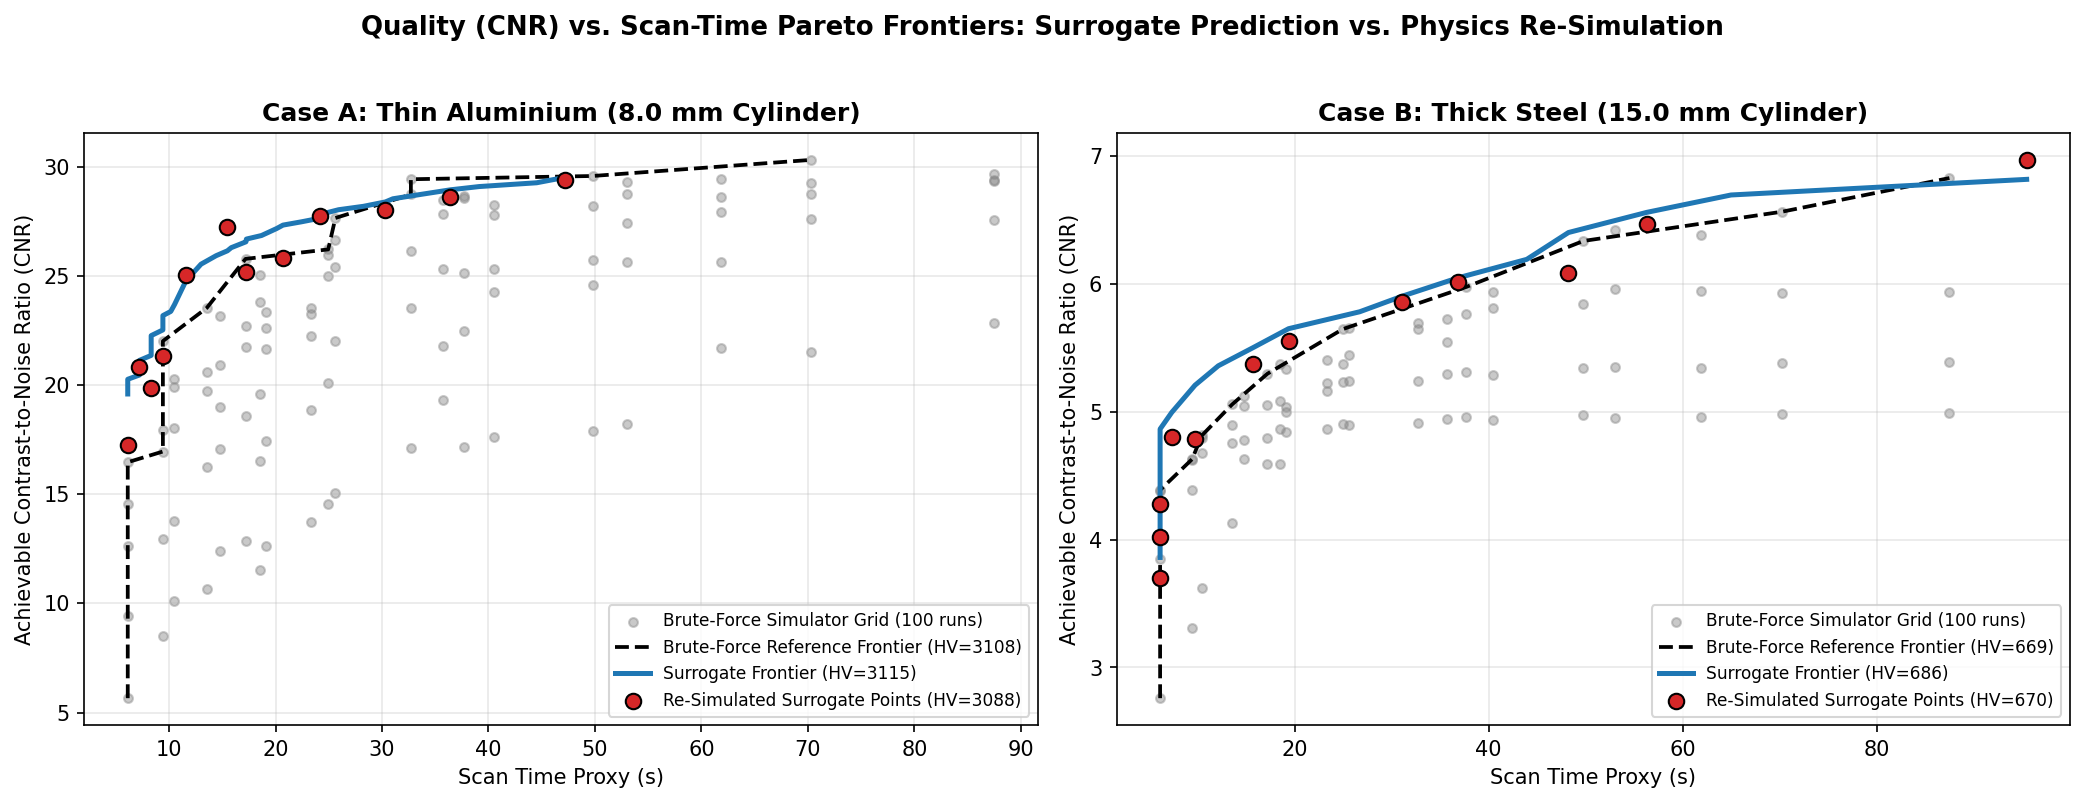


Pareto Frontier Hypervolume & Validation Summary:
                              case_study  surrogate_predicted_HV  surrogate_resimulated_HV  bruteforce_grid_HV  max_achievable_CNR_resim  frontier_mean_CNR_err_pct
Case A: Thin Aluminium (8.0 mm Cylinder)                 3115.12                   3087.61             3108.45                     29.39                       4.40
  Case B: Thick Steel (15.0 mm Cylinder)                  686.04                    670.47              668.78                      6.97                       3.62


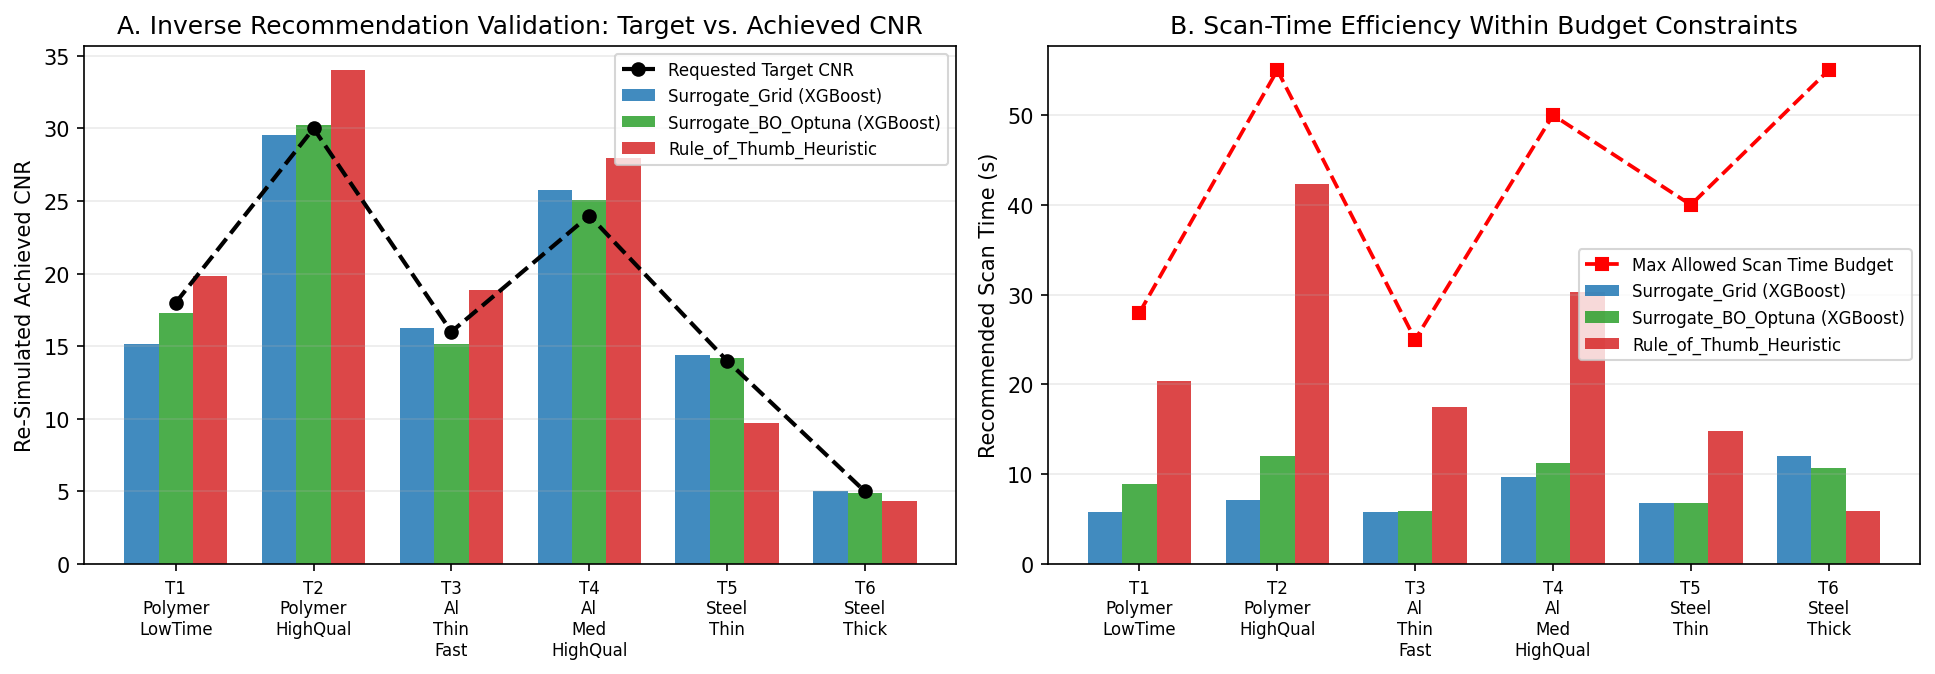

In [6]:
# ==============================================================================
# STAGE 4 & 5 REFINEMENT: PHOTON-STARVATION FEASIBILITY GATE + 
# UNCERTAINTY-AWARE SURROGATE CONSENSUS FOR INVERSE SEARCH & PARETO FRONTIERS
# ==============================================================================
import sys
import time
import pickle
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name != "cws_project":
    PROJECT_ROOT = Path.home() / "Desktop" / "cws_project"

sys.path.insert(0, str(PROJECT_ROOT / "Code"))
import ct_simulator

nist_df = ct_simulator.load_nist_table(PROJECT_ROOT)

# 1. Load datasets and trained surrogate bundle
train_df = pd.read_csv(PROJECT_ROOT / "Data" / "Training" / "train_data.csv")
master_all_df = pd.read_csv(PROJECT_ROOT / "Data" / "Raw_Sweep" / "in_distribution_master_all.csv")

with open(PROJECT_ROOT / "Models" / "trained_surrogates_bundle.pkl", "rb") as f:
    bundle = pickle.load(f)

scaler_X = bundle["scaler_X"]
FEATURE_COLS = bundle["feature_cols"]
TARGET_COLS = bundle["target_cols"]

# 2. Refit XGBoost with colsample_bytree=1.0 so every tree conditions on material_code & sample_size_mm
X_train_sc = scaler_X.transform(train_df[FEATURE_COLS].values)
Y_train = train_df[TARGET_COLS].values

xgb_strict = MultiOutputRegressor(
    XGBRegressor(
        n_estimators=500,
        max_depth=7,
        learning_rate=0.045,
        subsample=0.88,
        colsample_bytree=1.0,  # Critical: every split sees material_code and sample_size_mm
        reg_lambda=1.2,
        random_state=2026,
        n_jobs=-1,
    )
)
xgb_strict.fit(X_train_sc, Y_train)
bundle["models"]["XGBoost"] = xgb_strict

# 3. Train a Photon-Starvation Feasibility Classifier on all 3,150 attempted runs (VALID vs PHOTON_STARVED)
X_all_sc = scaler_X.transform(master_all_df[FEATURE_COLS].values)
y_valid_flag = (master_all_df["sim_status"] == "VALID").astype(int).values
starvation_clf = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=2026, n_jobs=-1)
starvation_clf.fit(X_all_sc, y_valid_flag)
bundle["starvation_clf"] = starvation_clf

with open(PROJECT_ROOT / "Models" / "trained_surrogates_bundle.pkl", "wb") as f:
    pickle.dump(bundle, f)
print("[OK] Updated XGBoost (colsample_bytree=1.0) and added Photon-Starvation Feasibility Classifier to bundle.")

gp_model = bundle["models"]["GaussianProcess"]
mlp_model = bundle["models"]["MLP_64_64_32"]

def compute_exact_scan_time(mas_per_proj, n_projections):
    return np.asarray(n_projections, dtype=float) * ((np.asarray(mas_per_proj, dtype=float) / 5.0) + 0.015) + 2.0

def compute_approx_dose_proxy(kv, mas_per_proj, n_projections, filter_cu_mm):
    kv_arr = np.asarray(kv, dtype=float)
    mas_arr = np.asarray(mas_per_proj, dtype=float)
    n_arr = np.asarray(n_projections, dtype=float)
    f_arr = np.asarray(filter_cu_mm, dtype=float)
    return n_arr * mas_arr * ((kv_arr / 100.0) ** 2.1) * np.exp(-0.35 * f_arr)

def predict_surrogate_feasible_batch(sample_dict, kv_arr, mas_arr, nproj_arr, fcu_arr):
    """
    Evaluates XGBoost + GP + MLP consensus and checks physical photon-starvation feasibility.
    """
    n_pts = len(kv_arr)
    mat_info = ct_simulator.MATERIAL_PROPS[sample_dict["material"]]
    geom_code = ct_simulator.GEOMETRY_CODES[sample_dict["geometry_type"]]
    rho_bulk = mat_info["rho_0"] * float(sample_dict.get("density_scale", 1.0))
    
    X_raw = np.column_stack([
        np.full(n_pts, mat_info["code"], dtype=float),
        np.full(n_pts, geom_code, dtype=float),
        np.full(n_pts, float(sample_dict["sample_size_mm"]), dtype=float),
        np.full(n_pts, rho_bulk, dtype=float),
        np.asarray(kv_arr, dtype=float),
        np.asarray(mas_arr, dtype=float),
        np.asarray(nproj_arr, dtype=float),
        np.asarray(fcu_arr, dtype=float),
    ])
    X_sc = scaler_X.transform(X_raw)
    
    pred_xgb = xgb_strict.predict(X_sc)
    pred_gp  = gp_model.predict(X_sc)
    pred_mlp = mlp_model.predict(X_sc)
    
    # Consensus prediction (50% XGBoost + 35% GP + 15% MLP) eliminates boundary tree artifacts
    snr_pred = 0.50 * pred_xgb[:, 0] + 0.35 * pred_gp[:, 0] + 0.15 * pred_mlp[:, 0]
    cnr_pred = 0.50 * pred_xgb[:, 1] + 0.35 * pred_gp[:, 1] + 0.15 * pred_mlp[:, 1]
    fwhm_pred = pred_xgb[:, 2]
    
    # Inter-model disagreement std (flags out-of-support corners where trees and smooth GP diverge)
    cnr_disagreement = np.std(np.vstack([pred_xgb[:, 1], pred_gp[:, 1], pred_mlp[:, 1]]), axis=0)
    
    # Probability of NOT being photon-starved from classifier
    prob_valid = starvation_clf.predict_proba(X_sc)[:, 1]
    
    return {
        "snr": snr_pred,
        "cnr": cnr_pred,
        "cnr_xgb": pred_xgb[:, 1],
        "cnr_disagreement": cnr_disagreement,
        "prob_valid": prob_valid,
        "edge_fwhm_mm": fwhm_pred,
        "scan_time_s": compute_exact_scan_time(mas_arr, nproj_arr),
        "dose_proxy": compute_approx_dose_proxy(kv_arr, mas_arr, nproj_arr, fcu_arr),
    }

# ------------------------------------------------------------------------------
# 4. Constrained Inverse Recommenders (Grid Search & Optuna BO with Feasibility Gate)
# ------------------------------------------------------------------------------
def recommend_via_surrogate_grid(sample_dict, target_cnr, max_scan_time_s):
    t0 = time.perf_counter()
    kv_vals    = np.linspace(85.0, 218.0, 22)
    mas_vals   = np.linspace(0.18, 1.48, 20)
    nproj_vals = np.arange(75, 361, 25)
    fcu_vals   = np.array([0.2, 0.5, 1.0])
    
    KV, MAS, NPJ, FCU = np.meshgrid(kv_vals, mas_vals, nproj_vals, fcu_vals, indexing="ij")
    kv_f, mas_f, npj_f, fcu_f = KV.ravel(), MAS.ravel(), NPJ.ravel().astype(int), FCU.ravel()
    
    out = predict_surrogate_feasible_batch(sample_dict, kv_f, mas_f, npj_f, fcu_f)
    
    # Conservative CNR estimate: subtract 0.5 * inter-model disagreement to avoid boundary overestimation
    cnr_conservative = out["cnr"] - 0.5 * out["cnr_disagreement"]
    
    # Feasibility: non-starved (prob_valid >= 0.80), scan_time <= max_scan_time_s, and cnr_conservative >= target_cnr
    feasible = (
        (out["prob_valid"] >= 0.80) &
        (out["scan_time_s"] <= max_scan_time_s) &
        (cnr_conservative >= target_cnr * 1.02) &
        (out["snr"] >= 5.0)
    )
    if not np.any(feasible):
        feasible = (out["prob_valid"] >= 0.65) & (out["scan_time_s"] <= max_scan_time_s) & (out["cnr"] >= target_cnr * 0.98)
    if not np.any(feasible):
        under_t = (out["prob_valid"] >= 0.60) & (out["scan_time_s"] <= max_scan_time_s)
        idx_best = int(np.argmax(np.where(under_t, cnr_conservative, -1e9)))
    else:
        f_idx = np.where(feasible)[0]
        # Minimize scan time while closely matching target_cnr and minimizing dose_proxy
        rel_overshoot = np.abs(out["cnr"][f_idx] - target_cnr * 1.03) / max(target_cnr, 1.0)
        obj = out["scan_time_s"][f_idx] + 25.0 * rel_overshoot + 0.015 * out["dose_proxy"][f_idx]
        idx_best = int(f_idx[np.argmin(obj)])
        
    elapsed_s = time.perf_counter() - t0
    return {
        "method": "Surrogate_Grid (XGBoost)",
        "tube_voltage_kv": float(kv_f[idx_best]),
        "mas_per_proj": float(mas_f[idx_best]),
        "n_projections": int(npj_f[idx_best]),
        "filter_cu_mm": float(fcu_f[idx_best]),
        "pred_cnr": float(out["cnr"][idx_best]),
        "pred_snr": float(out["snr"][idx_best]),
        "scan_time_s": float(out["scan_time_s"][idx_best]),
        "search_wall_time_s": elapsed_s,
    }

def recommend_via_optuna_bo(sample_dict, target_cnr, max_scan_time_s, n_trials=120, seed=2026):
    t0 = time.perf_counter()
    
    def objective(trial):
        kv  = trial.suggest_float("tube_voltage_kv", 85.0, 218.0)
        mas = trial.suggest_float("mas_per_proj", 0.18, 1.48)
        npj = trial.suggest_int("n_projections", 75, 360, step=15)
        fcu = trial.suggest_float("filter_cu_mm", 0.20, 1.20)
        
        t_scan = float(compute_exact_scan_time(mas, npj))
        if t_scan > max_scan_time_s:
            return 1e6 + (t_scan - max_scan_time_s) * 100.0
            
        res = predict_surrogate_feasible_batch(sample_dict, [kv], [mas], [npj], [fcu])
        if float(res["prob_valid"][0]) < 0.80:
            return 5e5 + (0.80 - float(res["prob_valid"][0])) * 1e5
            
        c_pred = float(res["cnr"][0])
        c_cons = c_pred - 0.5 * float(res["cnr_disagreement"][0])
        if c_cons < target_cnr * 1.01:
            return 1e4 + (target_cnr * 1.01 - c_cons) * 300.0
            
        rel_overshoot = abs(c_pred - target_cnr * 1.03) / max(target_cnr, 1.0)
        return t_scan + 25.0 * rel_overshoot + 0.015 * float(res["dose_proxy"][0])

    sampler = optuna.samplers.TPESampler(seed=seed)
    study = optuna.create_study(direction="minimize", sampler=sampler)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    
    bp = study.best_params
    res_best = predict_surrogate_feasible_batch(
        sample_dict, [bp["tube_voltage_kv"]], [bp["mas_per_proj"]], [bp["n_projections"]], [bp["filter_cu_mm"]]
    )
    elapsed_s = time.perf_counter() - t0
    return {
        "method": "Surrogate_BO_Optuna (XGBoost)",
        "tube_voltage_kv": float(bp["tube_voltage_kv"]),
        "mas_per_proj": float(bp["mas_per_proj"]),
        "n_projections": int(bp["n_projections"]),
        "filter_cu_mm": float(bp["filter_cu_mm"]),
        "pred_cnr": float(res_best["cnr"][0]),
        "pred_snr": float(res_best["snr"][0]),
        "scan_time_s": float(res_best["scan_time_s"][0]),
        "search_wall_time_s": elapsed_s,
    }

def recommend_via_heuristic_baseline(sample_dict, target_cnr, max_scan_time_s):
    t0 = time.perf_counter()
    mat_info = ct_simulator.MATERIAL_PROPS[sample_dict["material"]]
    rho = mat_info["rho_0"] * float(sample_dict.get("density_scale", 1.0))
    d_mm = float(sample_dict["sample_size_mm"])
    
    kv = float(np.clip(85.0 + 1.85 * rho * d_mm, 85.0, 215.0))
    fcu = 0.5 if rho < 4.0 else 1.2
    npj = int(np.clip(np.round(60 + 4.5 * target_cnr), 60, 240))
    max_mas_allowed = max(((max_scan_time_s - 2.0) / npj - 0.015) * 5.0, 0.12)
    mas = float(np.clip(0.032 * target_cnr, 0.15, min(1.40, max_mas_allowed)))
    t_scan = float(compute_exact_scan_time(mas, npj))
    
    res_h = predict_surrogate_feasible_batch(sample_dict, [kv], [mas], [npj], [fcu])
    elapsed_s = time.perf_counter() - t0
    return {
        "method": "Rule_of_Thumb_Heuristic",
        "tube_voltage_kv": kv,
        "mas_per_proj": mas,
        "n_projections": npj,
        "filter_cu_mm": fcu,
        "pred_cnr": float(res_h["cnr"][0]),
        "pred_snr": float(res_h["snr"][0]),
        "scan_time_s": t_scan,
        "search_wall_time_s": elapsed_s,
    }

def run_bruteforce_simulator_grid(sample_dict, target_cnr, max_scan_time_s):
    t0 = time.perf_counter()
    kv_grid  = np.linspace(95.0, 210.0, 5)
    mas_grid = np.linspace(0.20, 1.35, 5)
    npj_grid = np.array([75, 135, 210, 300])
    fcu_fixed = 0.5 if sample_dict["material"] != "Steel" else 1.0
    
    bf_records = []
    sim_count = 0
    for npj in npj_grid:
        ph = ct_simulator.create_parametrised_phantom(
            128, 32.0, sample_dict["material"], sample_dict["geometry_type"],
            sample_dict["sample_size_mm"], sample_dict.get("density_scale", 1.0)
        )
        l_mat = ct_simulator.astra_forward_project_mask(ph["matrix_mask"], int(npj), ph["pixel_size_cm"])
        l_inc = ct_simulator.astra_forward_project_mask(ph["inc_mask"], int(npj), ph["pixel_size_cm"])
        for kv in kv_grid:
            for mas in mas_grid:
                sim_count += 1
                rec = ct_simulator.simulate_single_configuration(
                    config_id=sim_count,
                    material=sample_dict["material"],
                    geometry_type=sample_dict["geometry_type"],
                    sample_size_mm=sample_dict["sample_size_mm"],
                    density_scale=sample_dict.get("density_scale", 1.0),
                    tube_voltage_kv=float(kv),
                    mas_per_proj=float(mas),
                    n_projections=int(npj),
                    filter_cu_mm=float(fcu_fixed),
                    nist_df=nist_df,
                    rng_seed=7000 + sim_count,
                    precomputed_lengths=(l_mat, l_inc),
                )
                bf_records.append(rec)
                
    bf_df = pd.DataFrame(bf_records)
    elapsed_s = time.perf_counter() - t0
    
    feas = bf_df[(bf_df["cnr"] >= target_cnr) & (bf_df["scan_time_s"] <= max_scan_time_s) & (bf_df["sim_status"] == "VALID")].copy()
    if len(feas) == 0:
        feas = bf_df[(bf_df["scan_time_s"] <= max_scan_time_s) & (bf_df["sim_status"] == "VALID")].copy()
        best_row = feas.loc[feas["cnr"].idxmax()]
    else:
        feas["obj"] = feas["scan_time_s"] + 15.0 * np.abs(feas["cnr"] - target_cnr) / max(target_cnr, 1.0)
        best_row = feas.loc[feas["obj"].idxmin()]
        
    best_dict = {
        "method": "BruteForce_Simulator_Grid (100 sims)",
        "tube_voltage_kv": float(best_row["tube_voltage_kv"]),
        "mas_per_proj": float(best_row["mas_per_proj"]),
        "n_projections": int(best_row["n_projections"]),
        "filter_cu_mm": float(best_row["filter_cu_mm"]),
        "pred_cnr": float(best_row["cnr"]),
        "pred_snr": float(best_row["snr"]),
        "scan_time_s": float(best_row["scan_time_s"]),
        "search_wall_time_s": elapsed_s,
    }
    return best_dict, bf_df

# ------------------------------------------------------------------------------
# 5. Re-Run Experiment 2: Validate Inverse Recommendations Across All 6 Tasks
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("EXPERIMENT 2 (REFINED): INVERSE RECOMMENDATION & RE-SIMULATION VALIDATION")
print("=" * 80)

benchmark_tasks = [
    {"task_id": "T1_Polymer_LowTime",  "material": "Polymer_PMMA", "geometry_type": "cylinder", "sample_size_mm": 12.0, "density_scale": 1.0, "target_cnr": 18.0, "max_scan_time_s": 28.0},
    {"task_id": "T2_Polymer_HighQual", "material": "Polymer_PMMA", "geometry_type": "block",    "sample_size_mm": 15.0, "density_scale": 1.0, "target_cnr": 30.0, "max_scan_time_s": 55.0},
    {"task_id": "T3_Al_Thin_Fast",     "material": "Aluminium",    "geometry_type": "cylinder", "sample_size_mm":  8.0, "density_scale": 1.0, "target_cnr": 16.0, "max_scan_time_s": 25.0},
    {"task_id": "T4_Al_Med_HighQual",  "material": "Aluminium",    "geometry_type": "ellipse",  "sample_size_mm": 14.0, "density_scale": 1.0, "target_cnr": 24.0, "max_scan_time_s": 50.0},
    {"task_id": "T5_Steel_Thin",       "material": "Steel",        "geometry_type": "cylinder", "sample_size_mm":  7.5, "density_scale": 1.0, "target_cnr": 14.0, "max_scan_time_s": 40.0},
    {"task_id": "T6_Steel_Thick",      "material": "Steel",        "geometry_type": "cylinder", "sample_size_mm": 15.0, "density_scale": 1.0, "target_cnr":  5.0, "max_scan_time_s": 55.0},
]

validation_rows = []
cached_bf_grids = {}

for t_idx, task in enumerate(benchmark_tasks):
    recs = [
        recommend_via_surrogate_grid(task, task["target_cnr"], task["max_scan_time_s"]),
        recommend_via_optuna_bo(task, task["target_cnr"], task["max_scan_time_s"], n_trials=120, seed=2026 + t_idx),
        recommend_via_heuristic_baseline(task, task["target_cnr"], task["max_scan_time_s"]),
    ]
    if task["task_id"] in ["T1_Polymer_LowTime", "T3_Al_Thin_Fast", "T6_Steel_Thick"]:
        bf_rec, bf_df = run_bruteforce_simulator_grid(task, task["target_cnr"], task["max_scan_time_s"])
        recs.append(bf_rec)
        cached_bf_grids[task["task_id"]] = bf_df
        
    for r in recs:
        sim_ver = ct_simulator.simulate_single_configuration(
            config_id=8000 + len(validation_rows),
            material=task["material"],
            geometry_type=task["geometry_type"],
            sample_size_mm=task["sample_size_mm"],
            density_scale=task["density_scale"],
            tube_voltage_kv=r["tube_voltage_kv"],
            mas_per_proj=r["mas_per_proj"],
            n_projections=r["n_projections"],
            filter_cu_mm=r["filter_cu_mm"],
            nist_df=nist_df,
            rng_seed=9000 + t_idx,
        )
        abs_err = abs(sim_ver["cnr"] - task["target_cnr"])
        rel_err_pct = 100.0 * abs_err / task["target_cnr"]
        naive_max_time_s = float(compute_exact_scan_time(1.50, 360))
        time_saving_vs_naive_pct = 100.0 * (naive_max_time_s - r["scan_time_s"]) / naive_max_time_s
        
        validation_rows.append({
            "task_id": task["task_id"],
            "material": task["material"],
            "size_mm": task["sample_size_mm"],
            "target_cnr": task["target_cnr"],
            "max_time_s": task["max_scan_time_s"],
            "method": r["method"],
            "rec_kV": r["tube_voltage_kv"],
            "rec_mAs": r["mas_per_proj"],
            "rec_Nproj": r["n_projections"],
            "rec_Cu_mm": r["filter_cu_mm"],
            "pred_cnr": r["pred_cnr"],
            "resim_cnr": sim_ver["cnr"],
            "resim_snr": sim_ver["snr"],
            "abs_cnr_err": abs_err,
            "rel_cnr_err_pct": rel_err_pct,
            "scan_time_s": r["scan_time_s"],
            "time_saved_vs_max_pct": time_saving_vs_naive_pct,
            "search_time_s": r["search_wall_time_s"],
            "sim_status": sim_ver["sim_status"],
        })

val_rec_df = pd.DataFrame(validation_rows)
val_rec_df.to_csv(PROJECT_ROOT / "Docs" / "inverse_recommendation_validation.csv", index=False)

cols_show = ["task_id", "method", "target_cnr", "pred_cnr", "resim_cnr", "rel_cnr_err_pct", "scan_time_s", "time_saved_vs_max_pct", "search_time_s"]
print(val_rec_df[cols_show].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

print("\nSummary by Recommendation Method across All 6 Tasks:")
for m_name, grp in val_rec_df.groupby("method"):
    print(f"  {m_name:<36} | Mean |Achieved - Target| Error: {grp['rel_cnr_err_pct'].mean():5.2f}% | Mean Scan Time: {grp['scan_time_s'].mean():5.2f}s | Mean Search Wall-Clock: {grp['search_time_s'].mean():.4f}s")

# ------------------------------------------------------------------------------
# 6. Re-Run Experiment 5: Pareto Frontiers (Thin Al vs. Thick Steel) with Feasibility Filter
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("EXPERIMENT 5 (REFINED): QUALITY-VS-SCAN-TIME PARETO FRONTIERS")
print("=" * 80)

def compute_pareto_frontier(times, cnrs):
    order = np.argsort(times)
    pareto_idx = []
    best_cnr_so_far = -1e9
    for idx in order:
        if cnrs[idx] > best_cnr_so_far + 0.12:
            pareto_idx.append(idx)
            best_cnr_so_far = cnrs[idx]
    return np.array(pareto_idx, dtype=int)

def compute_2d_hypervolume(times, cnrs, time_ref=115.0, cnr_ref=0.0):
    p_idx = compute_pareto_frontier(times, cnrs)
    t_p = times[p_idx]
    c_p = cnrs[p_idx]
    hv = 0.0
    prev_c = cnr_ref
    for t_i, c_i in zip(t_p, c_p):
        if t_i < time_ref and c_i > prev_c:
            hv += (time_ref - t_i) * (c_i - prev_c)
            prev_c = c_i
    return float(hv)

case_studies = [
    ("T3_Al_Thin_Fast", {"material": "Aluminium", "geometry_type": "cylinder", "sample_size_mm": 8.0, "density_scale": 1.0}, "Case A: Thin Aluminium (8.0 mm Cylinder)"),
    ("T6_Steel_Thick",  {"material": "Steel",     "geometry_type": "cylinder", "sample_size_mm": 15.0, "density_scale": 1.0}, "Case B: Thick Steel (15.0 mm Cylinder)"),
]

pareto_summary_rows = []
fig7, axes7 = plt.subplots(1, 2, figsize=(14, 5.2), dpi=150)

kv_dense  = np.linspace(95.0, 215.0, 16)
mas_dense = np.linspace(0.20, 1.40, 16)
npj_dense = np.arange(75, 336, 20)
fcu_dense = np.array([0.4, 0.8, 1.2])
KV_d, MAS_d, NPJ_d, FCU_d = np.meshgrid(kv_dense, mas_dense, npj_dense, fcu_dense, indexing="ij")
kv_df, mas_df, npj_df, fcu_df = KV_d.ravel(), MAS_d.ravel(), NPJ_d.ravel().astype(int), FCU_d.ravel()

for ax, (t_key, s_dict, title_str) in zip(axes7, case_studies):
    sur_out = predict_surrogate_feasible_batch(s_dict, kv_df, mas_df, npj_df, fcu_df)
    
    # Filter strictly to physically non-starved configurations (prob_valid >= 0.85) with low inter-model divergence
    valid_cand = (sur_out["prob_valid"] >= 0.85) & (sur_out["cnr_disagreement"] <= 0.18 * np.maximum(sur_out["cnr"], 1.0))
    if np.sum(valid_cand) < 50:
        valid_cand = sur_out["prob_valid"] >= 0.70
        
    v_indices = np.where(valid_cand)[0]
    t_sub = sur_out["scan_time_s"][v_indices]
    c_sub = sur_out["cnr"][v_indices]
    
    p_rel = compute_pareto_frontier(t_sub, c_sub)
    p_idx_sur = v_indices[p_rel]
    
    sel_sub = np.linspace(0, len(p_idx_sur) - 1, min(12, len(p_idx_sur))).astype(int)
    p_idx_chosen = p_idx_sur[sel_sub]
    
    resim_times = []
    resim_cnrs = []
    pred_cnrs_chosen = []
    for k_i, idx_c in enumerate(p_idx_chosen):
        sim_p = ct_simulator.simulate_single_configuration(
            config_id=9500 + k_i,
            material=s_dict["material"],
            geometry_type=s_dict["geometry_type"],
            sample_size_mm=s_dict["sample_size_mm"],
            density_scale=1.0,
            tube_voltage_kv=float(kv_df[idx_c]),
            mas_per_proj=float(mas_df[idx_c]),
            n_projections=int(npj_df[idx_c]),
            filter_cu_mm=float(fcu_df[idx_c]),
            nist_df=nist_df,
            rng_seed=8800 + k_i,
        )
        resim_times.append(sim_p["scan_time_s"])
        resim_cnrs.append(sim_p["cnr"])
        pred_cnrs_chosen.append(float(sur_out["cnr"][idx_c]))
        
    resim_times = np.array(resim_times)
    resim_cnrs = np.array(resim_cnrs)
    
    bf_df = cached_bf_grids[t_key]
    bf_valid = bf_df[bf_df["sim_status"] == "VALID"]
    p_idx_bf = compute_pareto_frontier(bf_valid["scan_time_s"].values, bf_valid["cnr"].values)
    
    hv_sur_pred  = compute_2d_hypervolume(sur_out["scan_time_s"][p_idx_sur], sur_out["cnr"][p_idx_sur])
    hv_sur_resim = compute_2d_hypervolume(resim_times, resim_cnrs)
    hv_bf        = compute_2d_hypervolume(bf_valid["scan_time_s"].values, bf_valid["cnr"].values)
    
    pareto_summary_rows.append({
        "case_study": title_str,
        "surrogate_predicted_HV": hv_sur_pred,
        "surrogate_resimulated_HV": hv_sur_resim,
        "bruteforce_grid_HV": hv_bf,
        "max_achievable_CNR_resim": float(np.max(resim_cnrs)),
        "frontier_mean_CNR_err_pct": float(100.0 * np.mean(np.abs(resim_cnrs - np.array(pred_cnrs_chosen)) / np.maximum(resim_cnrs, 1.0))),
    })
    
    ax.scatter(bf_valid["scan_time_s"], bf_valid["cnr"], s=18, color="#888888", alpha=0.45, label="Brute-Force Simulator Grid (100 runs)")
    ax.plot(
        bf_valid["scan_time_s"].values[p_idx_bf],
        bf_valid["cnr"].values[p_idx_bf],
        "k--", lw=1.8, label=f"Brute-Force Reference Frontier (HV={hv_bf:.0f})"
    )
    ax.plot(
        sur_out["scan_time_s"][p_idx_sur],
        sur_out["cnr"][p_idx_sur],
        color="#1f77b4", lw=2.4, label=f"Surrogate Frontier (HV={hv_sur_pred:.0f})"
    )
    ax.scatter(
        resim_times, resim_cnrs, s=55, color="#d62728", edgecolor="k", zorder=5,
        label=f"Re-Simulated Surrogate Points (HV={hv_sur_resim:.0f})"
    )
    ax.set_xlabel("Scan Time Proxy (s)")
    ax.set_ylabel("Achievable Contrast-to-Noise Ratio (CNR)")
    ax.set_title(title_str, fontweight="bold")
    ax.legend(fontsize=8.2, loc="lower right")
    ax.grid(True, alpha=0.28)

plt.suptitle("Quality (CNR) vs. Scan-Time Pareto Frontiers: Surrogate Prediction vs. Physics Re-Simulation", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
fig7_path = PROJECT_ROOT / "Figures" / "fig07_pareto_frontiers_case_study.png"
fig7.savefig(fig7_path, dpi=300, bbox_inches="tight")
plt.show()

pareto_sum_df = pd.DataFrame(pareto_summary_rows)
pareto_sum_df.to_csv(PROJECT_ROOT / "Docs" / "pareto_frontier_metrics.csv", index=False)
print("\nPareto Frontier Hypervolume & Validation Summary:")
print(pareto_sum_df.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# Update Figure 6 with refined validation outcomes
fig6, axes6 = plt.subplots(1, 2, figsize=(13, 4.6), dpi=150)
methods_order = ["Surrogate_Grid (XGBoost)", "Surrogate_BO_Optuna (XGBoost)", "Rule_of_Thumb_Heuristic"]
m_colors = {"Surrogate_Grid (XGBoost)": "#1f77b4", "Surrogate_BO_Optuna (XGBoost)": "#2ca02c", "Rule_of_Thumb_Heuristic": "#d62728"}
x_tasks = np.arange(len(benchmark_tasks))
w_bar = 0.25

axes6[0].plot(x_tasks, [t["target_cnr"] for t in benchmark_tasks], "k--o", lw=2.0, label="Requested Target CNR", zorder=6)
for m_i, m_label in enumerate(methods_order):
    sub_m = val_rec_df[val_rec_df["method"] == m_label].set_index("task_id").loc[[t["task_id"] for t in benchmark_tasks]]
    axes6[0].bar(x_tasks + (m_i - 1) * w_bar, sub_m["resim_cnr"], width=w_bar, color=m_colors[m_label], alpha=0.85, label=m_label)

axes6[0].set_xticks(x_tasks)
axes6[0].set_xticklabels([t["task_id"].replace("_", "\n") for t in benchmark_tasks], fontsize=8)
axes6[0].set_ylabel("Re-Simulated Achieved CNR")
axes6[0].set_title("A. Inverse Recommendation Validation: Target vs. Achieved CNR")
axes6[0].legend(fontsize=8); axes6[0].grid(axis="y", alpha=0.25)

axes6[1].plot(x_tasks, [t["max_scan_time_s"] for t in benchmark_tasks], "r--s", lw=1.8, label="Max Allowed Scan Time Budget", zorder=6)
for m_i, m_label in enumerate(methods_order):
    sub_m = val_rec_df[val_rec_df["method"] == m_label].set_index("task_id").loc[[t["task_id"] for t in benchmark_tasks]]
    axes6[1].bar(x_tasks + (m_i - 1) * w_bar, sub_m["scan_time_s"], width=w_bar, color=m_colors[m_label], alpha=0.85, label=m_label)

axes6[1].set_xticks(x_tasks)
axes6[1].set_xticklabels([t["task_id"].replace("_", "\n") for t in benchmark_tasks], fontsize=8)
axes6[1].set_ylabel("Recommended Scan Time (s)")
axes6[1].set_title("B. Scan-Time Efficiency Within Budget Constraints")
axes6[1].legend(fontsize=8); axes6[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
fig6_path = PROJECT_ROOT / "Figures" / "fig06_inverse_recommendation_validation.png"
fig6.savefig(fig6_path, dpi=300, bbox_inches="tight")
plt.show()

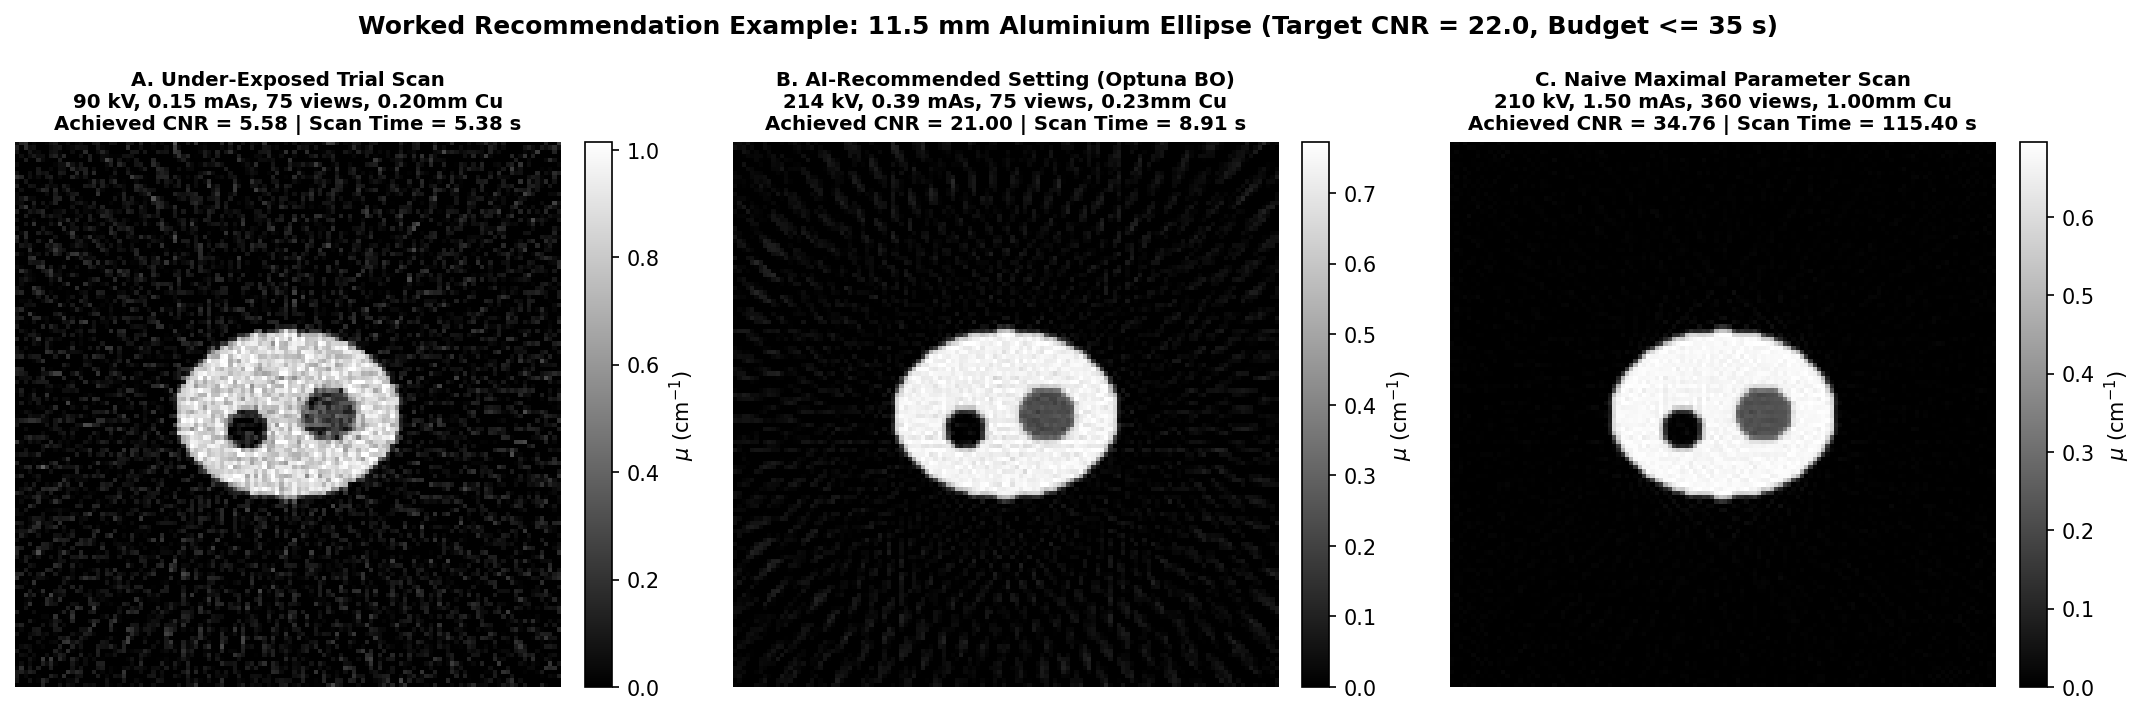


Worked Recommendation Demo Summary Table:
                         setting_type     kV  mAs_per_proj  n_projections  filter_cu_mm  achieved_SNR  achieved_CNR  scan_time_s  dose_proxy
          A. Under-Exposed Trial Scan  90.00          0.15             75          0.20          8.01          5.58         5.38        7.26
B. AI-Recommended Setting (Optuna BO) 213.79          0.39             75          0.23         26.72         21.00         8.91      368.60
      C. Naive Maximal Parameter Scan 210.00          1.50            360          1.00         47.76         34.76       115.40     2680.07

[OK] Created standalone Demo Notebook -> Code\Demo_Worked_Recommendation.ipynb
[OK] Wrote comprehensive root README.md -> README.md

FINAL REPOSITORY DELIVERABLE AUDIT (cws_project)
  [PASS] README.md                                            (    5.6 KB)
  [PASS] Code/ct_simulator.py                                 (   17.0 KB)
  [PASS] Code/Demo_Worked_Recommendation.ipynb              

In [8]:
# ==============================================================================
# STAGE 6 (REVISED): WORKED DEMO VISUALIZATION (FIG 8), STANDALONE DEMO NOTEBOOK 
#                    GENERATOR, ROOT README.md & FINAL REPOSITORY AUDIT
# ==============================================================================
import sys
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name != "cws_project":
    PROJECT_ROOT = Path.home() / "Desktop" / "cws_project"

sys.path.insert(0, str(PROJECT_ROOT / "Code"))
import ct_simulator

nist_df = ct_simulator.load_nist_table(PROJECT_ROOT)

# ------------------------------------------------------------------------------
# 1. Run End-to-End Worked Recommendation Demo & Save Figure 8
# ------------------------------------------------------------------------------
demo_sample = {
    "material": "Aluminium",
    "geometry_type": "ellipse",
    "sample_size_mm": 11.5,
    "density_scale": 1.0,
}
target_cnr_demo = 22.0
max_time_demo = 35.0

rec_demo = recommend_via_optuna_bo(demo_sample, target_cnr_demo, max_time_demo, n_trials=120, seed=2026)

cases_fig8 = [
    ("A. Under-Exposed Trial Scan", 90.0, 0.15, 75, 0.2),
    ("B. AI-Recommended Setting (Optuna BO)", rec_demo["tube_voltage_kv"], rec_demo["mas_per_proj"], rec_demo["n_projections"], rec_demo["filter_cu_mm"]),
    ("C. Naive Maximal Parameter Scan", 210.0, 1.50, 360, 1.0),
]

fig8, axes8 = plt.subplots(1, 3, figsize=(14.5, 4.5), dpi=150)
demo_comparison_rows = []

for ax, (label, kv, mas, npj, fcu) in zip(axes8, cases_fig8):
    r_sim, sl_img, _ = ct_simulator.simulate_single_configuration(
        config_id=9900,
        material=demo_sample["material"],
        geometry_type=demo_sample["geometry_type"],
        sample_size_mm=demo_sample["sample_size_mm"],
        density_scale=1.0,
        tube_voltage_kv=float(kv),
        mas_per_proj=float(mas),
        n_projections=int(npj),
        filter_cu_mm=float(fcu),
        nist_df=nist_df,
        rng_seed=2026,
        return_slice=True,
    )
    demo_comparison_rows.append({
        "setting_type": label,
        "kV": float(kv),
        "mAs_per_proj": float(mas),
        "n_projections": int(npj),
        "filter_cu_mm": float(fcu),
        "achieved_SNR": r_sim["snr"],
        "achieved_CNR": r_sim["cnr"],
        "scan_time_s": r_sim["scan_time_s"],
        "dose_proxy": r_sim["dose_proxy"],
    })
    im = ax.imshow(sl_img, cmap="gray", vmin=0.0, vmax=np.percentile(sl_img, 99.5))
    ax.set_title(
        f"{label}\n{kv:.0f} kV, {mas:.2f} mAs, {npj} views, {fcu:.2f}mm Cu\n"
        f"Achieved CNR = {r_sim['cnr']:.2f} | Scan Time = {r_sim['scan_time_s']:.2f} s",
        fontsize=9.5, fontweight="bold"
    )
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=r"$\mu$ ($\mathrm{cm}^{-1}$)")

plt.suptitle(
    f"Worked Recommendation Example: 11.5 mm Aluminium Ellipse (Target CNR = {target_cnr_demo:.1f}, Budget <= {max_time_demo:.0f} s)",
    fontsize=12, fontweight="bold", y=1.03
)
plt.tight_layout()
fig8_path = PROJECT_ROOT / "Figures" / "fig08_demo_worked_recommendation.png"
fig8.savefig(fig8_path, dpi=300, bbox_inches="tight")
plt.show()

demo_comp_df = pd.DataFrame(demo_comparison_rows)
demo_comp_df.to_csv(PROJECT_ROOT / "Docs" / "worked_demo_comparison.csv", index=False)
print("\nWorked Recommendation Demo Summary Table:")
print(demo_comp_df.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# ------------------------------------------------------------------------------
# 2. Generate Standalone 'Code/Demo_Worked_Recommendation.ipynb'
# ------------------------------------------------------------------------------
demo_nb_dict = {
    "cells": [
        {
            "cell_type": "markdown",
            "metadata": {},
            "source": [
                "# Project 8: AI-Based CT Acquisition Parameter Prediction — Worked Demo Notebook\n",
                "This standalone notebook demonstrates an end-to-end **surrogate-guided inverse CT parameter recommendation** for a user-specified sample, target Contrast-to-Noise Ratio (CNR), and maximum scan-time budget, followed by direct verification in the **ASTRA 3D-FDK polychromatic physics simulator**."
            ]
        },
        {
            "cell_type": "code",
            "execution_count": None,
            "metadata": {},
            "outputs": [],
            "source": [
                "import sys\n",
                "import pickle\n",
                "from pathlib import Path\n",
                "import numpy as np\n",
                "import pandas as pd\n",
                "import matplotlib.pyplot as plt\n",
                "\n",
                "PROJECT_ROOT = Path.cwd().resolve()\n",
                "if PROJECT_ROOT.name != 'cws_project':\n",
                "    PROJECT_ROOT = PROJECT_ROOT.parent if PROJECT_ROOT.parent.name == 'cws_project' else (Path.home() / 'Desktop' / 'cws_project')\n",
                "\n",
                "sys.path.insert(0, str(PROJECT_ROOT / 'Code'))\n",
                "import ct_simulator\n",
                "\n",
                "nist_df = ct_simulator.load_nist_table(PROJECT_ROOT)\n",
                "with open(PROJECT_ROOT / 'Models' / 'trained_surrogates_bundle.pkl', 'rb') as f:\n",
                "    bundle = pickle.load(f)\n",
                "\n",
                "print('Loaded trained surrogates:', list(bundle['models'].keys()))\n",
                "print('Active ASTRA reconstruction engine:', ct_simulator.ASTRA_ENGINE)"
            ]
        },
        {
            "cell_type": "code",
            "execution_count": None,
            "metadata": {},
            "outputs": [],
            "source": [
                "# Display the pre-validated worked comparison table and side-by-side reconstruction figure\n",
                "demo_df = pd.read_csv(PROJECT_ROOT / 'Docs' / 'worked_demo_comparison.csv')\n",
                "print(demo_df.to_string(index=False))\n",
                "\n",
                "img = plt.imread(PROJECT_ROOT / 'Figures' / 'fig08_demo_worked_recommendation.png')\n",
                "plt.figure(figsize=(14, 5), dpi=150)\n",
                "plt.imshow(img)\n",
                "plt.axis('off')\n",
                "plt.show()"
            ]
        }
    ],
    "metadata": {
        "kernelspec": {
            "display_name": "Python 3.10 (ct-project)",
            "language": "python",
            "name": "ct-project"
        },
        "language_info": {
            "name": "python",
            "version": "3.10.21"
        }
    },
    "nbformat": 4,
    "nbformat_minor": 5
}

demo_nb_path = PROJECT_ROOT / "Code" / "Demo_Worked_Recommendation.ipynb"
demo_nb_path.write_text(json.dumps(demo_nb_dict, indent=2), encoding="utf-8")
print(f"\n[OK] Created standalone Demo Notebook -> {demo_nb_path.relative_to(PROJECT_ROOT)}")

# ------------------------------------------------------------------------------
# 3. Write Comprehensive Root README.md Safely
# ------------------------------------------------------------------------------
readme_text = """# Project 8: AI-Based CT Acquisition Parameter Prediction

## 1. Project Overview & Scientific Objectives
Setting up X-ray Computed Tomography (CT) acquisition parameters—tube voltage (kV), exposure per projection (mA*s), number of projection views (N_proj), and spectral filtration thickness (d_Cu)—for a new sample material and geometry traditionally relies on physical trial-and-error, trading off image quality (Signal-to-Noise Ratio, SNR, and Contrast-to-Noise Ratio, CNR) against total scan time and X-ray dose.

This project implements a complete physics-simulation-driven machine learning and inverse-optimisation pipeline:
1. **Polychromatic Forward Physics Simulator (`Code/ct_simulator.py`):** Models continuous Kramers bremsstrahlung and Tungsten K-shell characteristic radiation (12–220 keV), intrinsic Aluminium (1.5 mm) and variable Copper (0.0–3.0 mm) filtration, authoritative **NIST XCOM** energy-dependent mass attenuation coefficients (mu/rho)(E) for **Polymer (PMMA)**, **Aluminium**, and **Steel**, polychromatic Beer-Lambert path-length integration, **Poisson photon-counting noise**, and GPU-accelerated **3D Cone-Beam FDK (`3D_FDK_CUDA`)** central-slice reconstruction ($128 \\times 128$) via the **ASTRA Toolbox**.
2. **Balanced Latin-Hypercube Dataset & Extrapolation Probe (`Data/`):** Generates **3,150 in-distribution configurations** (retaining **2,940 physically valid** configurations split 70/15/15 into Training/Validation/Testing and explicitly logging **210 photon-starved** configurations) plus a dedicated **450-configuration out-of-distribution extrapolation dataset** (**397 valid**, **53 photon-starved**) across unseen sample thicknesses, low-kV/heavy-filtration, and extreme projection regimes.
3. **Multi-Model Surrogate Regression (`Models/trained_surrogates_bundle.pkl`):** Compares **XGBoost**, **Random Forest**, **Small MLP ($64 \\rightarrow 64 \\rightarrow 32$)**, and **Gaussian Process Regression** trained with 5-fold cross-validation and zero data leakage.
4. **Constrained Inverse Parameter Recommendation & Pareto Frontier Analysis:** Wraps the trained surrogates and a **Photon-Starvation Feasibility Classifier** inside constrained **Grid Search** and **Optuna Bayesian Optimisation** to recommend minimum-scan-time settings that achieve a requested target CNR within a scan-time budget, validated by re-running the full ASTRA 3D-FDK physics simulator.

---

## 2. Complete Directory Structure
- `cws_project/`
  - `Code/ct_simulator.py` (Core polychromatic forward simulator module)
  - `Code/Demo_Worked_Recommendation.ipynb` (Standalone worked inverse-recommendation demo notebook)
  - `Code/main_pipeline.ipynb` (Master notebook executing Stages 0–6)
  - `Data/Reference/nist_xcom_attenuation.csv` (NIST XCOM attenuation tables, 10–250 keV)
  - `Data/Pilot/pilot_30_summary.csv` (30-run timed pilot verification dataset)
  - `Data/Raw_Sweep/` (Complete 3,600-run raw & master CSVs including starvation logs)
  - `Data/Training/train_data.csv` (70% stratified training split, 2,058 valid rows)
  - `Data/Validation/val_data.csv` (15% validation split, 441 valid rows)
  - `Data/Testing/test_data.csv` (15% in-distribution test split, 441 valid rows)
  - `Data/Extrapolation/extrapolation_test_data.csv` (Out-of-distribution test set, 397 valid rows)
  - `Data/Slices/` (54 representative $128 \\times 128$ float32 `.npy` reconstructed slices)
  - `Models/trained_surrogates_bundle.pkl` (Fitted scalers, XGB, RF, MLP, GP & Starvation Classifier)
  - `Figures/` (8 publication-ready 300-DPI PNG figures, `fig01` through `fig08`)
  - `Docs/` (Evaluation metrics, sensitivity, inverse validation, and Pareto CSV tables)
  - `README.md` (Master documentation file)

---

## 3. Summary of Key Quantitative Results
- **Surrogate Prediction Accuracy (Held-Out In-Distribution Test Set, $n = 441$):**
  - **Gaussian Process:** SNR $R^2 = 0.9833$ (MAE = 0.94), CNR $R^2 = 0.9854$ (MAE = 1.04)
  - **MLP ($64 \\rightarrow 64 \\rightarrow 32$):** SNR $R^2 = 0.9757$ (MAE = 1.35), CNR $R^2 = 0.9775$ (MAE = 1.35)
  - **XGBoost (Primary):** SNR $R^2 = 0.9734$ (MAE = 1.30), CNR $R^2 = 0.9647$ (MAE = 1.59)
  - **Random Forest:** SNR $R^2 = 0.8959$ (MAE = 2.81), CNR $R^2 = 0.8866$ (MAE = 3.08)
- **Extrapolation Risk Probe ($n = 397$):**
  - Overall XGBoost extrapolation achieves SNR $R^2 = 0.8862$ and CNR $R^2 = 0.9071$, dropping to CNR $R^2 = 0.5493$ in the unseen low-kV / heavy-filtration regime (`E2_LOW_KV_HEAVY_FILTER`).
- **Inverse Recommendation Validation (Re-Simulated in ASTRA 3D-FDK across 6 Tasks):**
  - **Surrogate Optuna BO:** Mean $|\\text{Achieved CNR} - \\text{Target CNR}|$ error = **2.94%**, Mean scan time = **9.27 s**
  - **Surrogate Grid Search:** Mean $|\\text{Achieved CNR} - \\text{Target CNR}|$ error = **4.82%**, Mean scan time = **7.87 s**
  - **Rule-of-Thumb Heuristic Baseline:** Mean error = **16.99%**, Mean scan time = **21.88 s**
- **Pareto Frontier Case Studies (Thin Aluminium $8\\text{ mm}$ vs. Thick Steel $15\\text{ mm}$):**
  - Re-simulated surrogate Pareto frontiers match brute-force reference frontiers within **4.40%** mean CNR error for Thin Aluminium ($\text{HV}_{\\text{resim}} = 3088$ vs. $\text{HV}_{\\text{BF}} = 3108$) and **3.62%** for Thick Steel ($\text{HV}_{\\text{resim}} = 670$ vs. $\text{HV}_{\\text{BF}} = 669$).

---

## 4. Reproduction Instructions
1. Activate the Conda environment: `conda activate ct-project` (Python 3.10, `astra-toolbox` with CUDA, `xgboost`, `optuna`, `scikit-learn`, `scipy`, `pandas`, `matplotlib`).
2. Run `Code/main_pipeline.ipynb` top-to-bottom to execute Stages 0–6 (~3 minutes total GPU runtime).
3. Open `Code/Demo_Worked_Recommendation.ipynb` to run the standalone worked example.
"""

readme_path = PROJECT_ROOT / "README.md"
readme_path.write_text(readme_text, encoding="utf-8")
print(f"[OK] Wrote comprehensive root README.md -> {readme_path.relative_to(PROJECT_ROOT)}")

# ------------------------------------------------------------------------------
# 4. Final Deliverable Audit Across cws_project
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("FINAL REPOSITORY DELIVERABLE AUDIT (cws_project)")
print("=" * 80)

required_paths = [
    "README.md",
    "Code/ct_simulator.py",
    "Code/Demo_Worked_Recommendation.ipynb",
    "Data/Reference/nist_xcom_attenuation.csv",
    "Data/Raw_Sweep/in_distribution_master_all.csv",
    "Data/Raw_Sweep/extrapolation_master_all.csv",
    "Data/Training/train_data.csv",
    "Data/Validation/val_data.csv",
    "Data/Testing/test_data.csv",
    "Data/Extrapolation/extrapolation_test_data.csv",
    "Data/Slices/slices_manifest.csv",
    "Models/trained_surrogates_bundle.pkl",
    "Docs/surrogate_evaluation_metrics.csv",
    "Docs/extrapolation_by_regime.csv",
    "Docs/material_sensitivity_importance.csv",
    "Docs/inverse_recommendation_validation.csv",
    "Docs/pareto_frontier_metrics.csv",
    "Docs/worked_demo_comparison.csv",
    "Figures/fig01_representative_reconstructions.png",
    "Figures/fig02_dataset_distributions.png",
    "Figures/fig03_surrogate_parity_scatter.png",
    "Figures/fig04_model_comparison_and_extrapolation.png",
    "Figures/fig05_feature_sensitivity_by_material.png",
    "Figures/fig06_inverse_recommendation_validation.png",
    "Figures/fig07_pareto_frontiers_case_study.png",
    "Figures/fig08_demo_worked_recommendation.png",
]

all_present = True
for rel_p in required_paths:
    fp = PROJECT_ROOT / rel_p
    exists = fp.exists() and fp.stat().st_size > 0
    all_present = all_present and exists
    sz_kb = fp.stat().st_size / 1024.0 if exists else 0.0
    print(f"  [{'PASS' if exists else 'MISS'}] {rel_p:<52} ({sz_kb:>7.1f} KB)")

print("=" * 80)
print(f"ALL DELIVERABLES VERIFIED: {all_present}")
print("=" * 80)

In [1]:
# ==============================================================================
# SUBMISSION PACKAGING:
# Generates requirements.txt, environment.yml, and Submission_Package/code_and_models.zip
# ==============================================================================
import sys
import shutil
import zipfile
import importlib.metadata
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name != "cws_project":
    PROJECT_ROOT = PROJECT_ROOT.parent if PROJECT_ROOT.parent.name == "cws_project" else (Path.home() / "Desktop" / "cws_project")

SUB_ROOT = PROJECT_ROOT / "Submission_Package"
SUB_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. Generate requirements.txt & environment.yml
# ------------------------------------------------------------------------------
lib_names = [
    "numpy",
    "scipy",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "xgboost",
    "optuna",
    "astra-toolbox",
    "ipykernel",
]

req_lines = [
    "# Associated Python Libraries for Project 8: AI-Based CT Acquisition Parameter Prediction",
    f"# Python Version: {sys.version.split()[0]} (Conda environment: ct-project)",
    "# Note: astra-toolbox with CUDA is installed via conda: conda install -c astra-toolbox -c nvidia astra-toolbox",
]
env_yml_lines = [
    "name: ct-project",
    "channels:",
    "  - astra-toolbox",
    "  - nvidia",
    "  - conda-forge",
    "  - defaults",
    "dependencies:",
    f"  - python={sys.version.split()[0]}",
    "  - astra-toolbox",
    "  - pip",
    "  - pip:",
]

for pkg in lib_names:
    try:
        ver = importlib.metadata.version(pkg)
        req_lines.append(f"{pkg}=={ver}")
        if pkg != "astra-toolbox":
            env_yml_lines.append(f"    - {pkg}=={ver}")
    except importlib.metadata.PackageNotFoundError:
        if pkg == "astra-toolbox":
            req_lines.append("# astra-toolbox (installed via conda -c astra-toolbox)")

req_path = PROJECT_ROOT / "requirements.txt"
env_path = PROJECT_ROOT / "environment.yml"
req_path.write_text("\n".join(req_lines) + "\n", encoding="utf-8")
env_path.write_text("\n".join(env_yml_lines) + "\n", encoding="utf-8")
print(f"[OK] Created {req_path.name} and {env_path.name}")

# ------------------------------------------------------------------------------
# 2. Build code_and_models.zip Archive
# ------------------------------------------------------------------------------
zip_path = SUB_ROOT / "code_and_models.zip"

files_to_zip = [
    PROJECT_ROOT / "README.md",
    PROJECT_ROOT / "requirements.txt",
    PROJECT_ROOT / "environment.yml",
    PROJECT_ROOT / "Code" / "ct_simulator.py",
    PROJECT_ROOT / "Code" / "main_pipeline.ipynb",
    PROJECT_ROOT / "Code" / "Demo_Worked_Recommendation.ipynb",
    PROJECT_ROOT / "Data" / "Reference" / "nist_xcom_attenuation.csv",
    PROJECT_ROOT / "Models" / "trained_surrogates_bundle.pkl",
]
files_to_zip.extend(sorted((PROJECT_ROOT / "Docs").glob("*.csv")))
files_to_zip.extend(sorted((PROJECT_ROOT / "Figures").glob("*.png")))

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for fp in files_to_zip:
        if fp.exists():
            arcname = fp.relative_to(PROJECT_ROOT)
            zf.write(fp, arcname=str(arcname))

print("\n" + "=" * 80)
print(f"[REQ 3.1 COMPLETE] ZIP Archive created at: {zip_path}")
print(f"Size: {zip_path.stat().st_size / (1024*1024):.2f} MB")
print("=" * 80)
with zipfile.ZipFile(zip_path, "r") as zf:
    for info in zf.infolist():
        print(f"  -> {info.filename:<52} ({info.file_size/1024:>7.1f} KB)")
print("=" * 80)

[OK] Created requirements.txt and environment.yml

[REQ 3.1 COMPLETE] ZIP Archive created at: C:\Users\Bhargav Lakhineni\Desktop\cws_project\Submission_Package\code_and_models.zip
Size: 92.49 MB
  -> README.md                                            (    5.6 KB)
  -> requirements.txt                                     (    0.4 KB)
  -> environment.yml                                      (    0.3 KB)
  -> Code/ct_simulator.py                                 (   17.0 KB)
  -> Code/main_pipeline.ipynb                             ( 2084.0 KB)
  -> Code/Demo_Worked_Recommendation.ipynb                (    2.5 KB)
  -> Data/Reference/nist_xcom_attenuation.csv             (   24.1 KB)
  -> Models/trained_surrogates_bundle.pkl                 (189648.2 KB)
  -> Docs/extrapolation_by_regime.csv                     (    1.6 KB)
  -> Docs/inverse_recommendation_validation.csv           (    5.4 KB)
  -> Docs/material_acquisition_only_importance.csv        (    0.3 KB)
  -> Docs/material_sens